# Contact distance analysis - WT vs S466R

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Protein DBD with DNA

### Load data

In [2]:
wt_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004_contacts/pairs_dbd.csv')
    wt_dbd_dfs.append(df)

S466R_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/004_contacts/pairs_dbd.csv')
    S466R_dbd_dfs.append(df)

In [3]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,190,MET,A,12,DG,D,4.907506
1,1000,190,MET,A,12,DG,D,4.486903
2,1000,192,THR,A,12,DG,D,4.632156
3,1000,192,THR,A,11,DC,D,4.287577
4,1000,192,THR,A,11,DC,D,4.939452


### Preprocessing

Adjust residue numbers.

In [4]:
def adjust_resid(dfs):
    for df in (dfs):
        df["sele1_resid_adj"] = np.where(
            df["sele1_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele1_resid"] + 135,
            df["sele1_resid"]
        )
        df["sele2_resid_adj"] = np.where(
            df["sele2_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele2_resid"] + 135,
            df["sele2_resid"]
    )

In [5]:
adjust_resid(wt_dbd_dfs + S466R_dbd_dfs)

In [6]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,190,MET,A,12,DG,D,4.907506,325,12
1,1000,190,MET,A,12,DG,D,4.486903,325,12
2,1000,192,THR,A,12,DG,D,4.632156,327,12
3,1000,192,THR,A,11,DC,D,4.287577,327,11
4,1000,192,THR,A,11,DC,D,4.939452,327,11


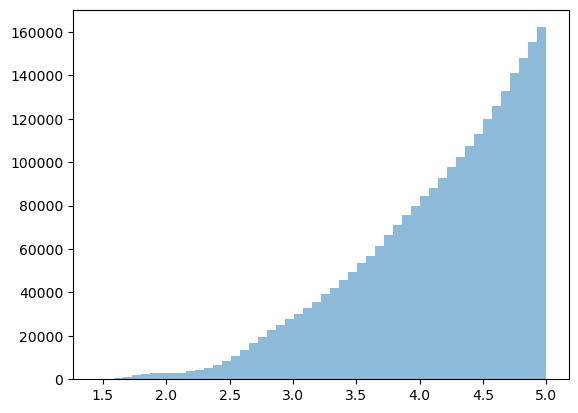

In [7]:
plt.hist(wt_dbd_dfs[0]['distance'], bins=50, alpha=0.5, label='wt', )
plt.show()

Note that each contact is associated with two residues, but no specific atoms. For this reason, a residue pair might be present multiple times in a single frame and, as seen next, dividing the count of a pair by the total number of frames might result in a value higher than 100. 

In [8]:
def aggregate_pairs(df_list):
    combined = pd.concat(df_list)
    
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 'sele1_chain', 
                              'sele2_resnm', 'sele2_resid_adj', 'sele2_chain']).agg(
        count=('distance', 'size'), 
        distance_avg=('distance', 'mean') 
    ).reset_index()
    
    return agg_df

In [9]:
wt_dbd_agg = aggregate_pairs(wt_dbd_dfs)
S466R_dbd_agg = aggregate_pairs(S466R_dbd_dfs)

In [10]:
wt_dbd_agg.sort_values('distance_avg', ascending=True).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg
181,GLY,422,B,DT,7,D,21063,3.887578
376,THR,419,B,DT,8,D,24459,3.906081
80,ASN,460,B,DA,15,C,54834,3.961775
356,THR,417,B,DA,21,C,6766,3.967327
94,GLN,340,A,DC,11,D,29475,4.011293
11,ARG,378,A,DT,8,C,101445,4.012405
173,GLY,422,A,DG,6,C,91321,4.017636
371,THR,419,B,DA,21,C,24643,4.024574
99,GLN,340,B,DC,11,C,83039,4.027218
120,GLN,463,B,DT,8,D,85619,4.036318


In [11]:
wt_dbd_agg["count_avg"] = wt_dbd_agg["count"] / (len(wt_dbd_dfs)* 1000)
S466R_dbd_agg["count_avg"] = S466R_dbd_agg["count"] / (len(S466R_dbd_dfs)* 1000)

In [12]:
wt_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
36,ARG,418,B,DG,19,C,283033,4.145784,94.344333
302,SER,459,A,DT,8,C,278783,4.098669,92.927667
38,ARG,418,B,DT,7,D,257178,4.160853,85.726000
114,GLN,463,A,DT,7,C,202698,4.101309,67.566000
391,VAL,339,B,DC,11,C,178984,4.136174,59.661333
337,THR,327,A,DC,11,D,168211,4.138601,56.070333
34,ARG,418,B,DC,20,C,167178,4.146232,55.726000
26,ARG,418,A,DG,20,D,159261,4.104046,53.087000
415,VAL,461,B,DG,13,C,142352,4.174150,47.450667
89,ASN,460,B,DT,8,D,125384,4.173410,41.794667


In [13]:
S466R_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
359,SER,459,A,DT,8,C,205346,4.088663,68.448667
142,GLN,463,B,DT,7,D,175829,4.143801,58.609667
36,ARG,418,A,DG,20,D,156227,4.141812,52.075667
58,ARG,466,B,DA,6,D,151940,4.051493,50.646667
366,SER,459,B,DT,8,D,135910,4.188848,45.303333
136,GLN,463,A,DT,7,C,129901,4.144781,43.300333
35,ARG,418,A,DG,6,C,112648,4.125752,37.549333
449,VAL,339,B,DC,11,C,112446,4.118608,37.482000
289,LYS,410,A,DT,9,C,108447,4.154764,36.149000
49,ARG,418,B,DG,19,C,105074,4.092648,35.024667


### Comparison

In [14]:
def pivotdf_count_avg(df):
    pivot = df.pivot_table(values='count_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

In [15]:
wt_dbd_pivot = pivotdf_count_avg(wt_dbd_agg)
mut_dbd_pivot = pivotdf_count_avg(S466R_dbd_agg)

In [16]:
wt_dbd_pivot.head()

sele1_resid_adj,325,326,327,328,329,330,331,336,337,338,...,429,457,458,459,460,461,462,463,464,466
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.002667,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0005,NaN,0.033167,1.773167,NaN,0.0015


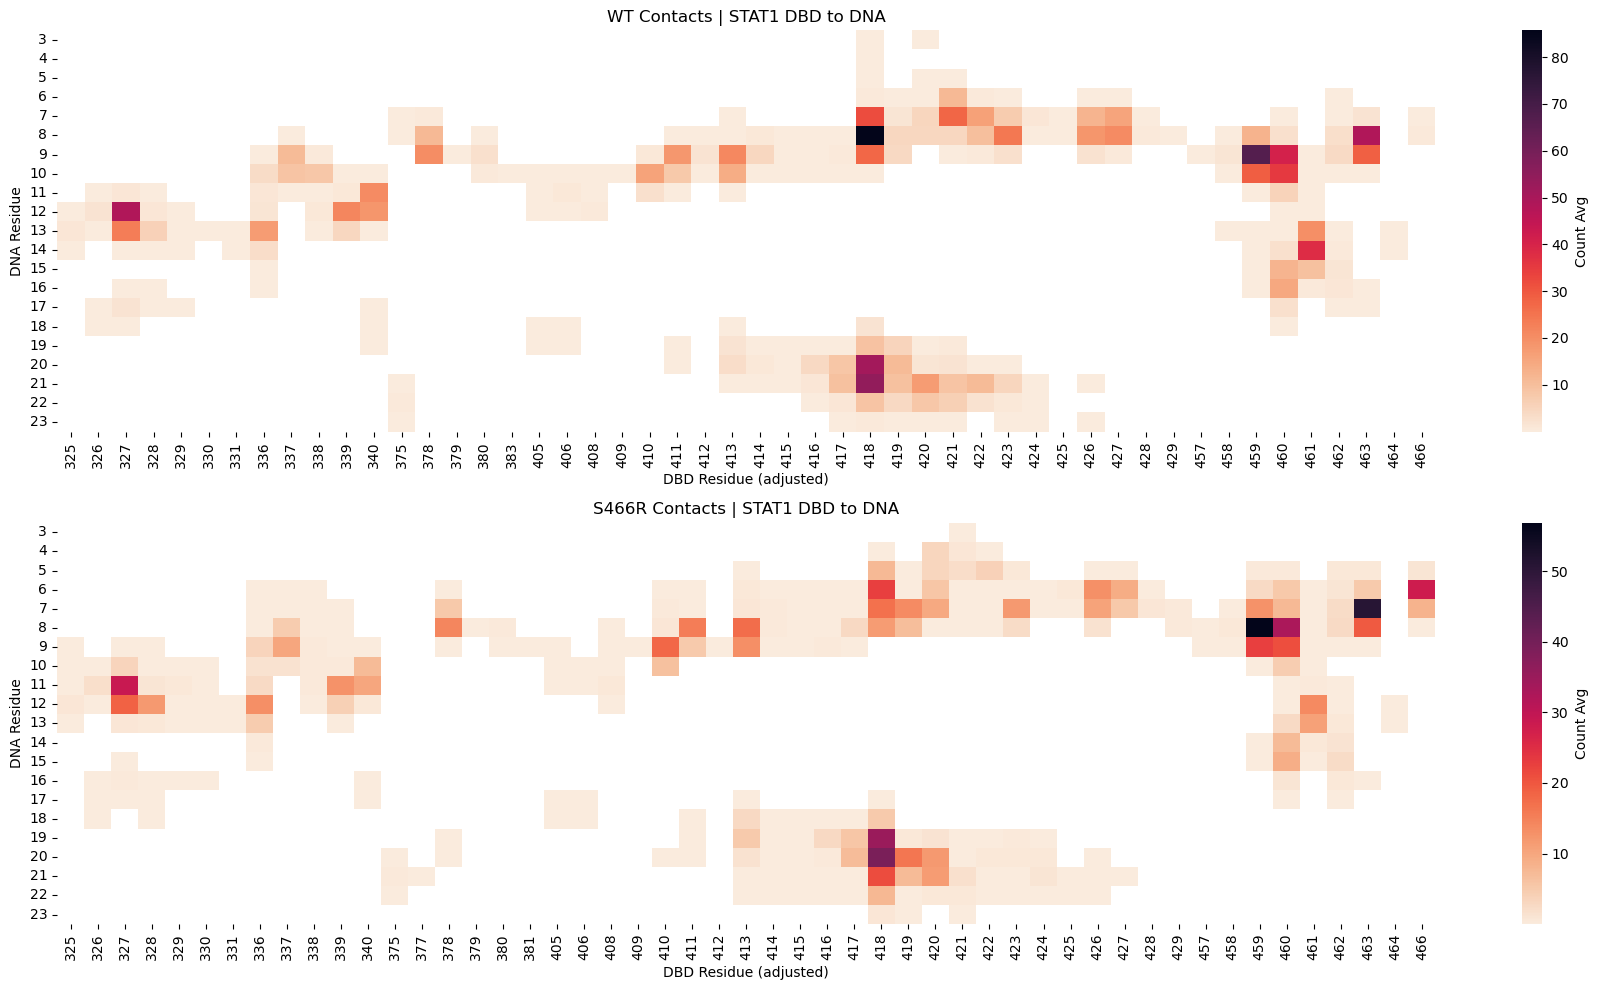

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# S466R heatmap
sns.heatmap(mut_dbd_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('S466R Contacts | STAT1 DBD to DNA')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

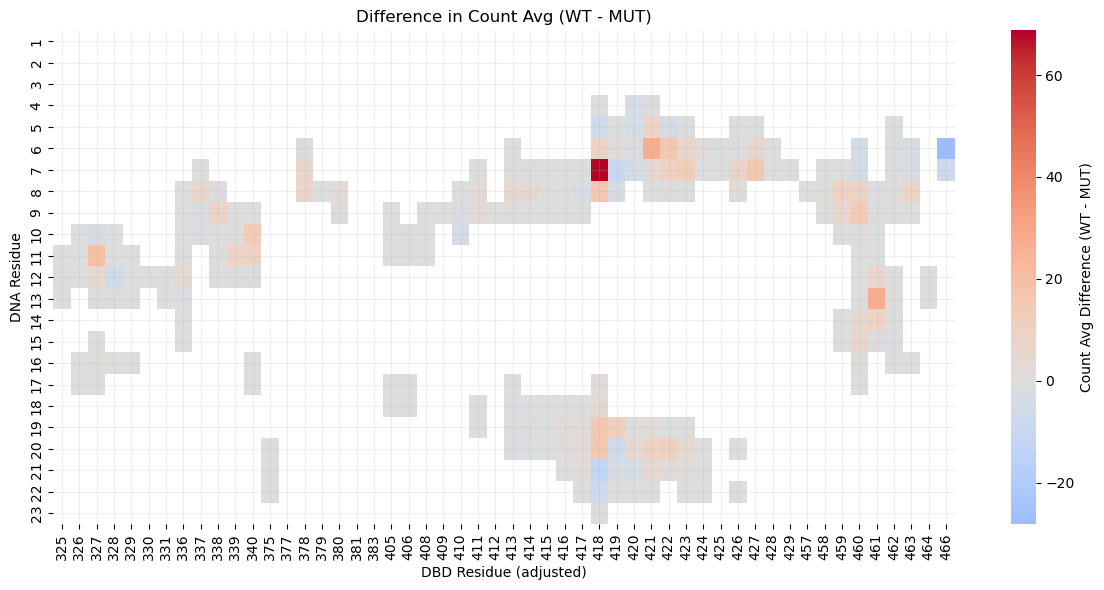

In [18]:
diff_dbd_pivot = wt_dbd_pivot - mut_dbd_pivot

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By chain

In [19]:
wt_dbd_agg['sele1_chain'].value_counts()

sele1_chain
A    210
B    209
Name: count, dtype: int64

In [20]:
wt_dbd_agg_monoA = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'A']
wt_dbd_agg_monoB = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'B']

In [21]:
S466R_dbd_agg['sele1_chain'].value_counts()

sele1_chain
B    247
A    241
Name: count, dtype: int64

In [22]:
S466R_dbd_agg_monoA = S466R_dbd_agg[S466R_dbd_agg['sele1_chain'] == 'A']
S466R_dbd_agg_monoB = S466R_dbd_agg[S466R_dbd_agg['sele1_chain'] == 'B']

In [23]:
wt_dbd_monoA_pivot = pivotdf_count_avg(wt_dbd_agg_monoA)
wt_dbd_monoB_pivot = pivotdf_count_avg(wt_dbd_agg_monoB)
mut_dbd_monoA_pivot = pivotdf_count_avg(S466R_dbd_agg_monoA)
mut_dbd_monoB_pivot = pivotdf_count_avg(S466R_dbd_agg_monoB)

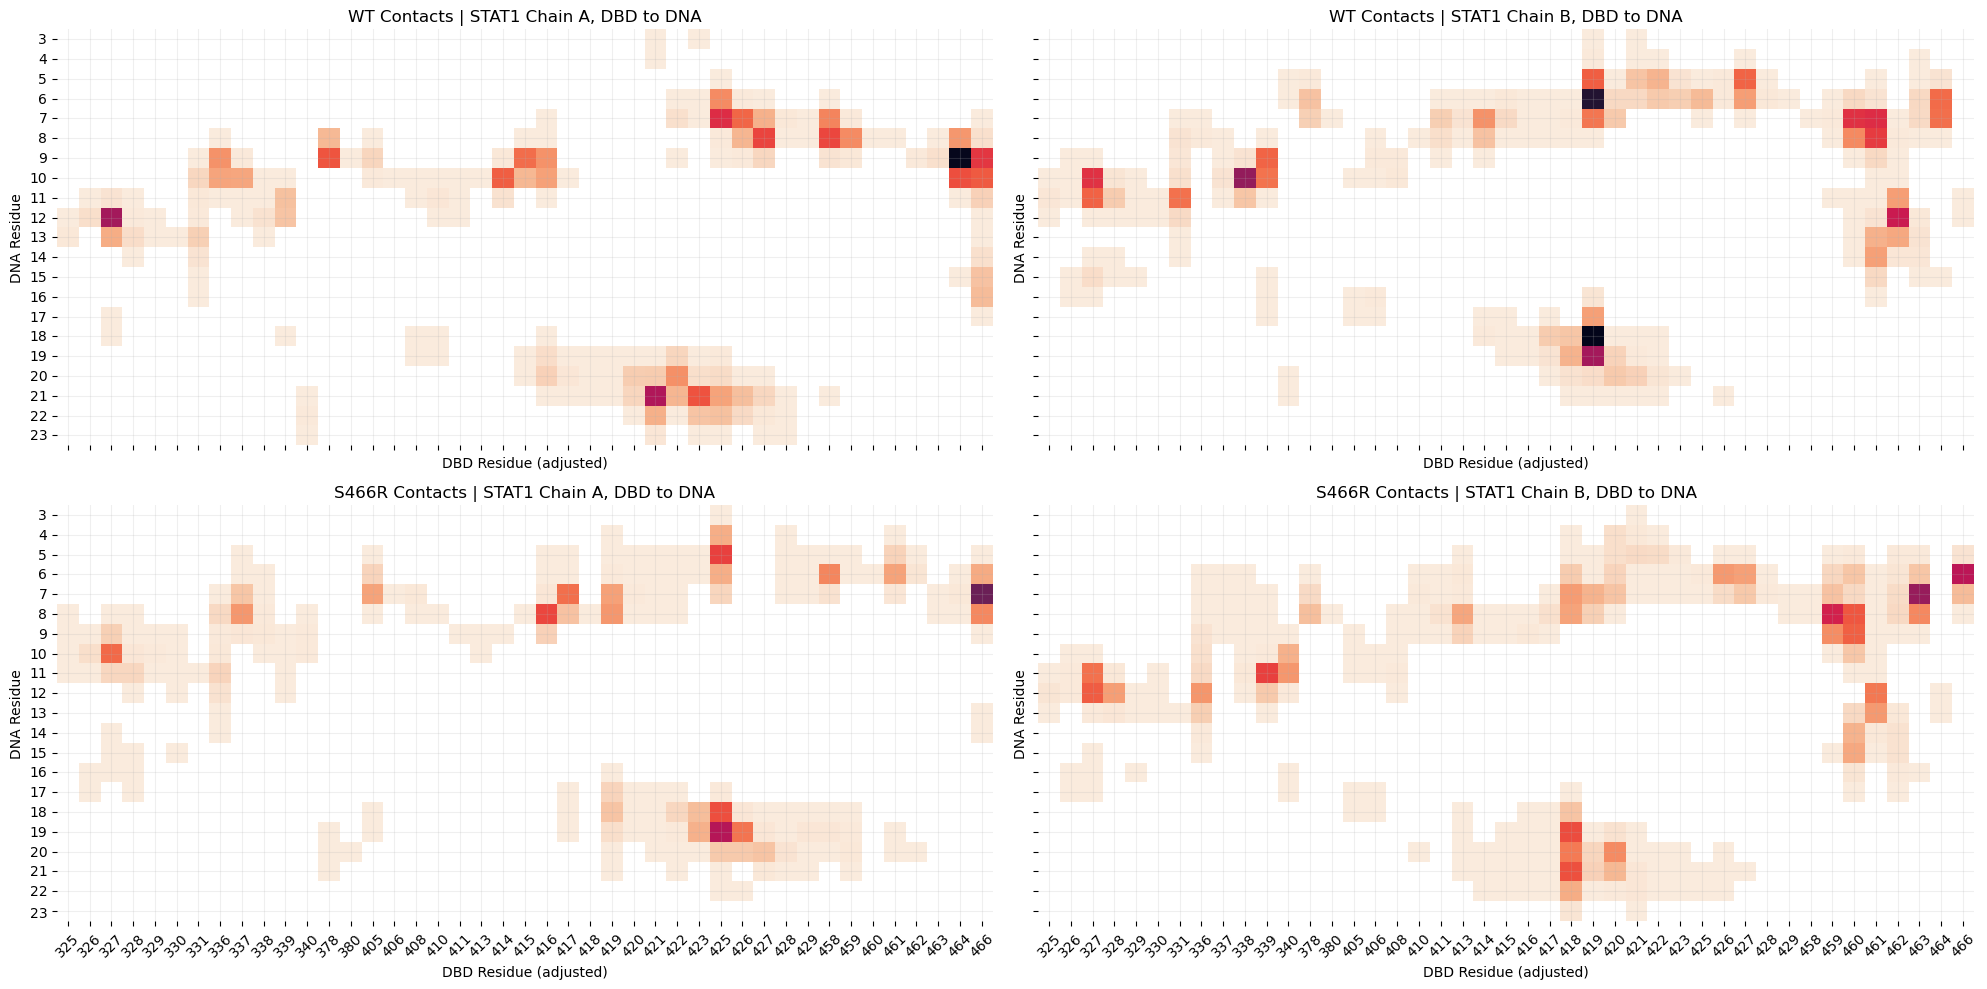

In [24]:
# Find global min and max
all_data = [
    wt_dbd_monoA_pivot.values,
    wt_dbd_monoB_pivot.values,
    mut_dbd_monoA_pivot.values,
    mut_dbd_monoB_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_pivot, ax1, 'WT Contacts | STAT1 Chain A, DBD to DNA'),
    (wt_dbd_monoB_pivot, ax2, 'WT Contacts | STAT1 Chain B, DBD to DNA'),
    (mut_dbd_monoA_pivot, ax3, 'S466R Contacts | STAT1 Chain A, DBD to DNA'),
    (mut_dbd_monoB_pivot, ax4, 'S466R Contacts | STAT1 Chain B, DBD to DNA')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)

# Rotate x-axis labels for all axes
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

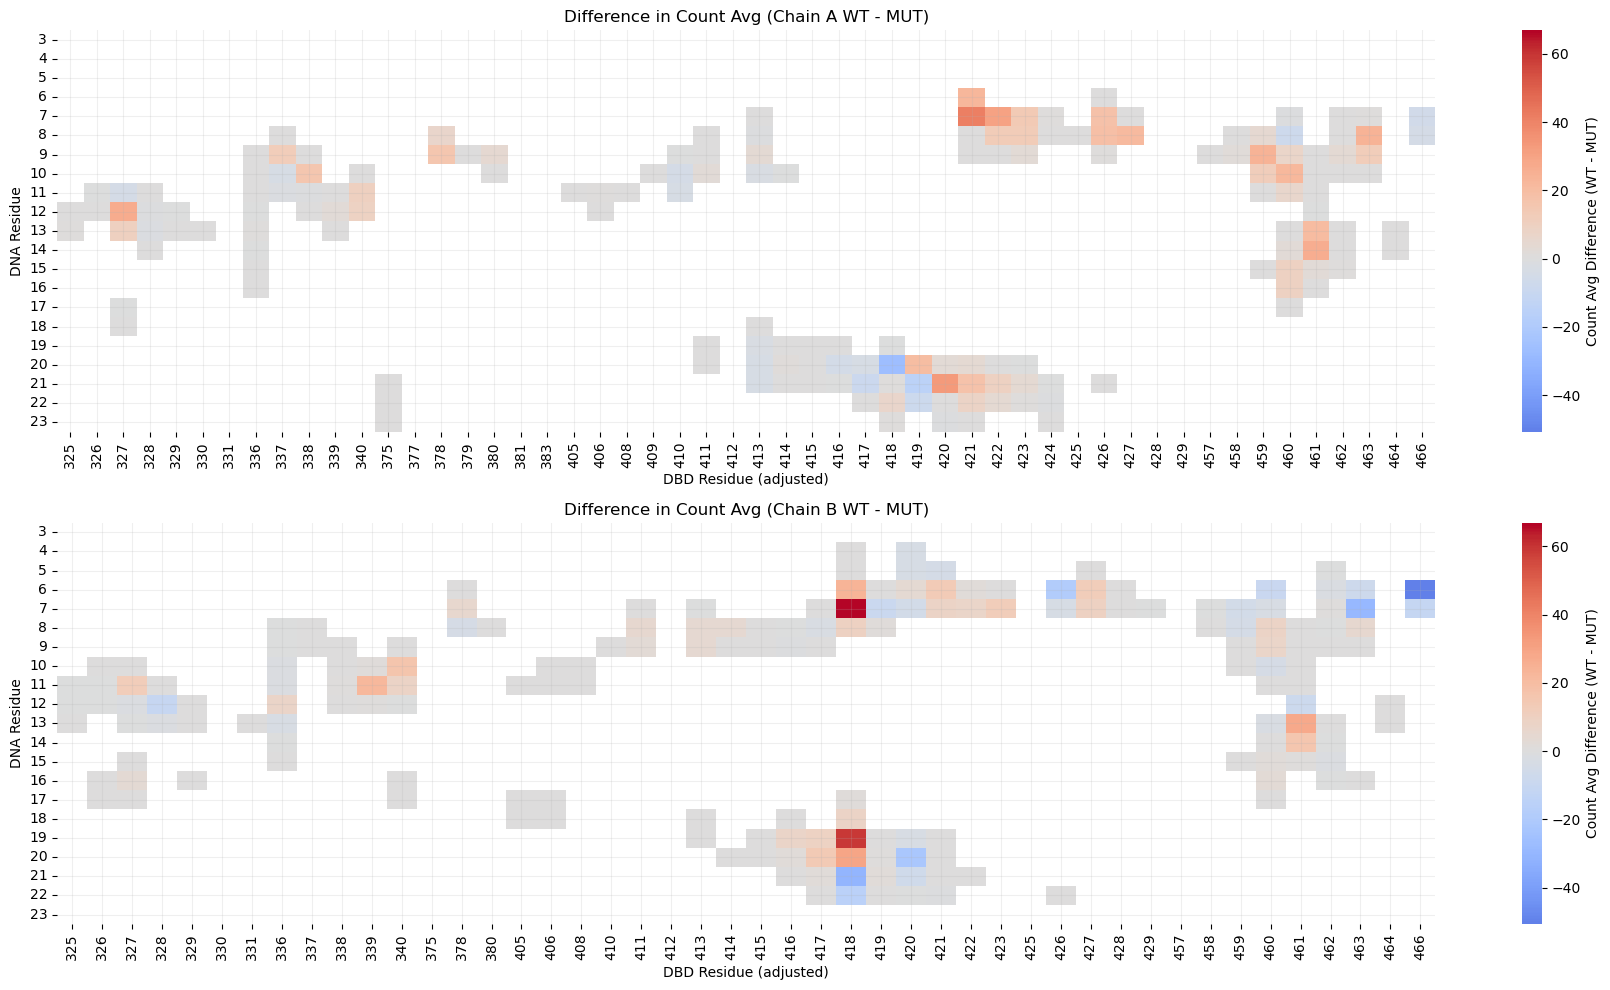

In [26]:
diff_dbd_monoA_pivot = wt_dbd_monoA_pivot - mut_dbd_monoA_pivot
diff_dbd_monoB_pivot = wt_dbd_monoB_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_monoA_pivot.values,
    diff_dbd_monoB_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# Chain A
sns.heatmap(diff_dbd_monoA_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax1.set_title('Difference in Count Avg (Chain A WT - MUT)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Chain B
sns.heatmap(diff_dbd_monoB_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax2.set_title('Difference in Count Avg (Chain B WT - MUT)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

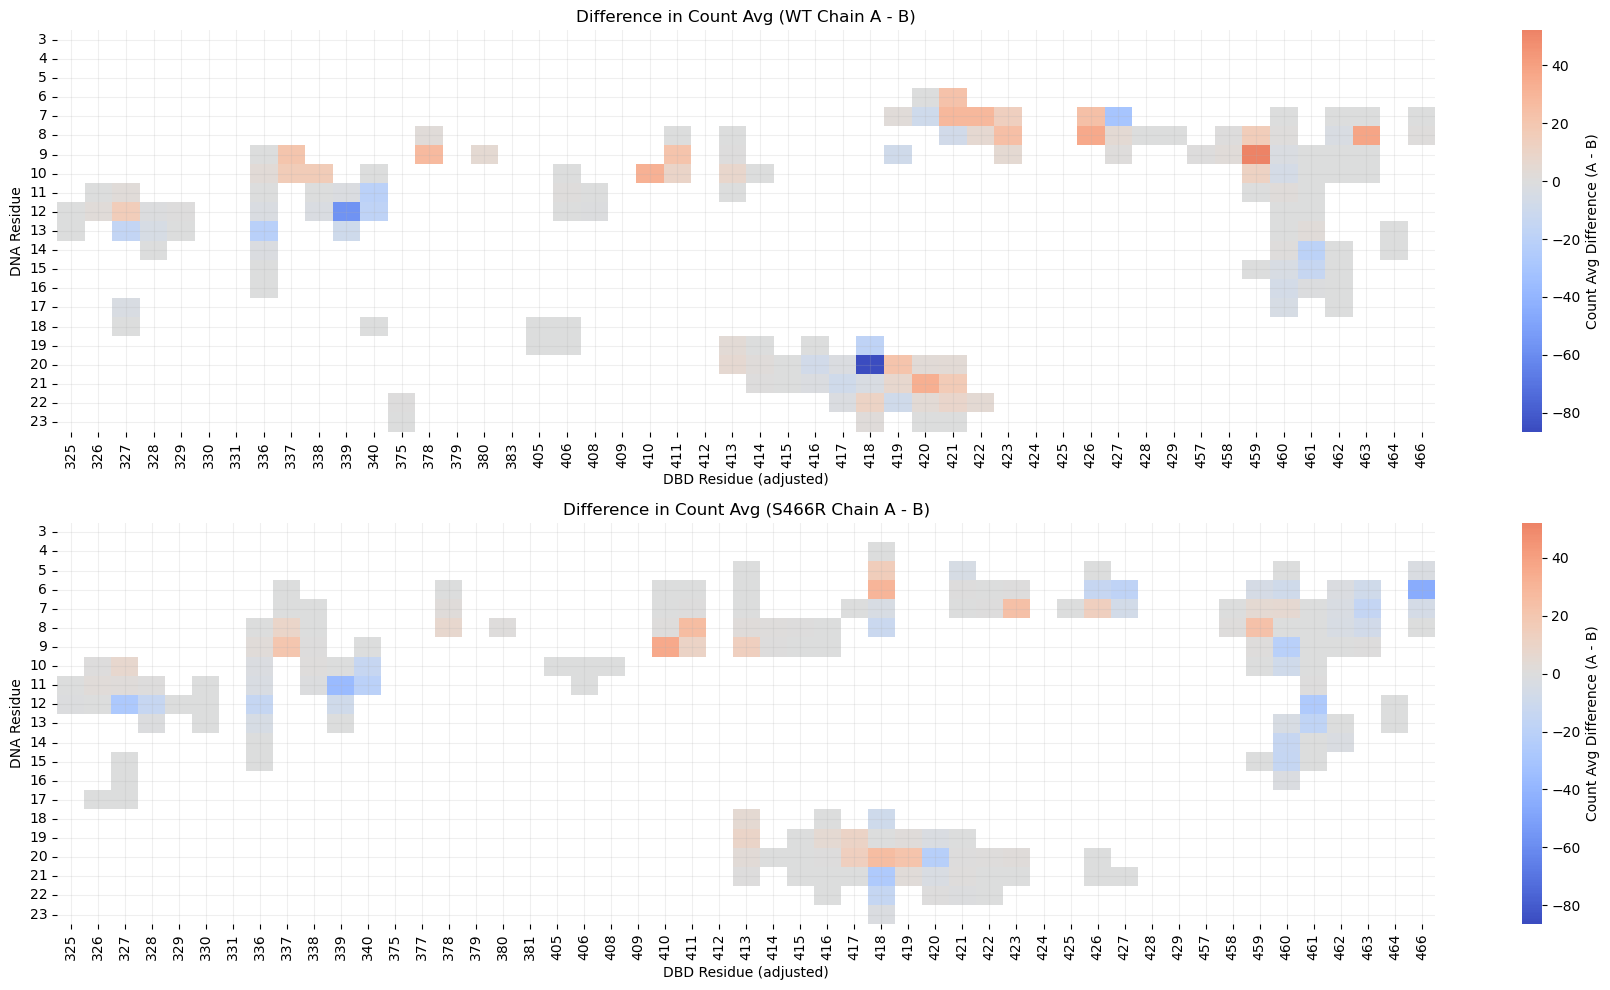

In [27]:
diff_dbd_wt_pivot = wt_dbd_monoA_pivot - wt_dbd_monoB_pivot
diff_dbd_mut_pivot = mut_dbd_monoA_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_pivot.values,
    diff_dbd_mut_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT
sns.heatmap(diff_dbd_wt_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax1.set_title('Difference in Count Avg (WT Chain A - B)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Chain B
sns.heatmap(diff_dbd_mut_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax2.set_title('Difference in Count Avg (S466R Chain A - B)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

#### By Chain and DNA strand

In [28]:
wt_dbd_agg_monoA_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoA_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'D')]
wt_dbd_agg_monoB_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoB_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'D')]

wt_dbd_monoA_C_pivot = pivotdf_count_avg(wt_dbd_agg_monoA_C)
wt_dbd_monoA_D_pivot = pivotdf_count_avg(wt_dbd_agg_monoA_D)
wt_dbd_monoB_C_pivot = pivotdf_count_avg(wt_dbd_agg_monoB_C)
wt_dbd_monoB_D_pivot = pivotdf_count_avg(wt_dbd_agg_monoB_D)

S466R_dbd_agg_monoA_C = S466R_dbd_agg[(S466R_dbd_agg['sele1_chain'] == 'A') & (S466R_dbd_agg['sele2_chain'] == 'C')]
S466R_dbd_agg_monoA_D = S466R_dbd_agg[(S466R_dbd_agg['sele1_chain'] == 'A') & (S466R_dbd_agg['sele2_chain'] == 'D')]
S466R_dbd_agg_monoB_C = S466R_dbd_agg[(S466R_dbd_agg['sele1_chain'] == 'B') & (S466R_dbd_agg['sele2_chain'] == 'C')]
S466R_dbd_agg_monoB_D = S466R_dbd_agg[(S466R_dbd_agg['sele1_chain'] == 'B') & (S466R_dbd_agg['sele2_chain'] == 'D')]

mut_dbd_monoA_C_pivot = pivotdf_count_avg(S466R_dbd_agg_monoA_C)
mut_dbd_monoA_D_pivot = pivotdf_count_avg(S466R_dbd_agg_monoA_D)
mut_dbd_monoB_C_pivot = pivotdf_count_avg(S466R_dbd_agg_monoB_C)
mut_dbd_monoB_D_pivot = pivotdf_count_avg(S466R_dbd_agg_monoB_D)

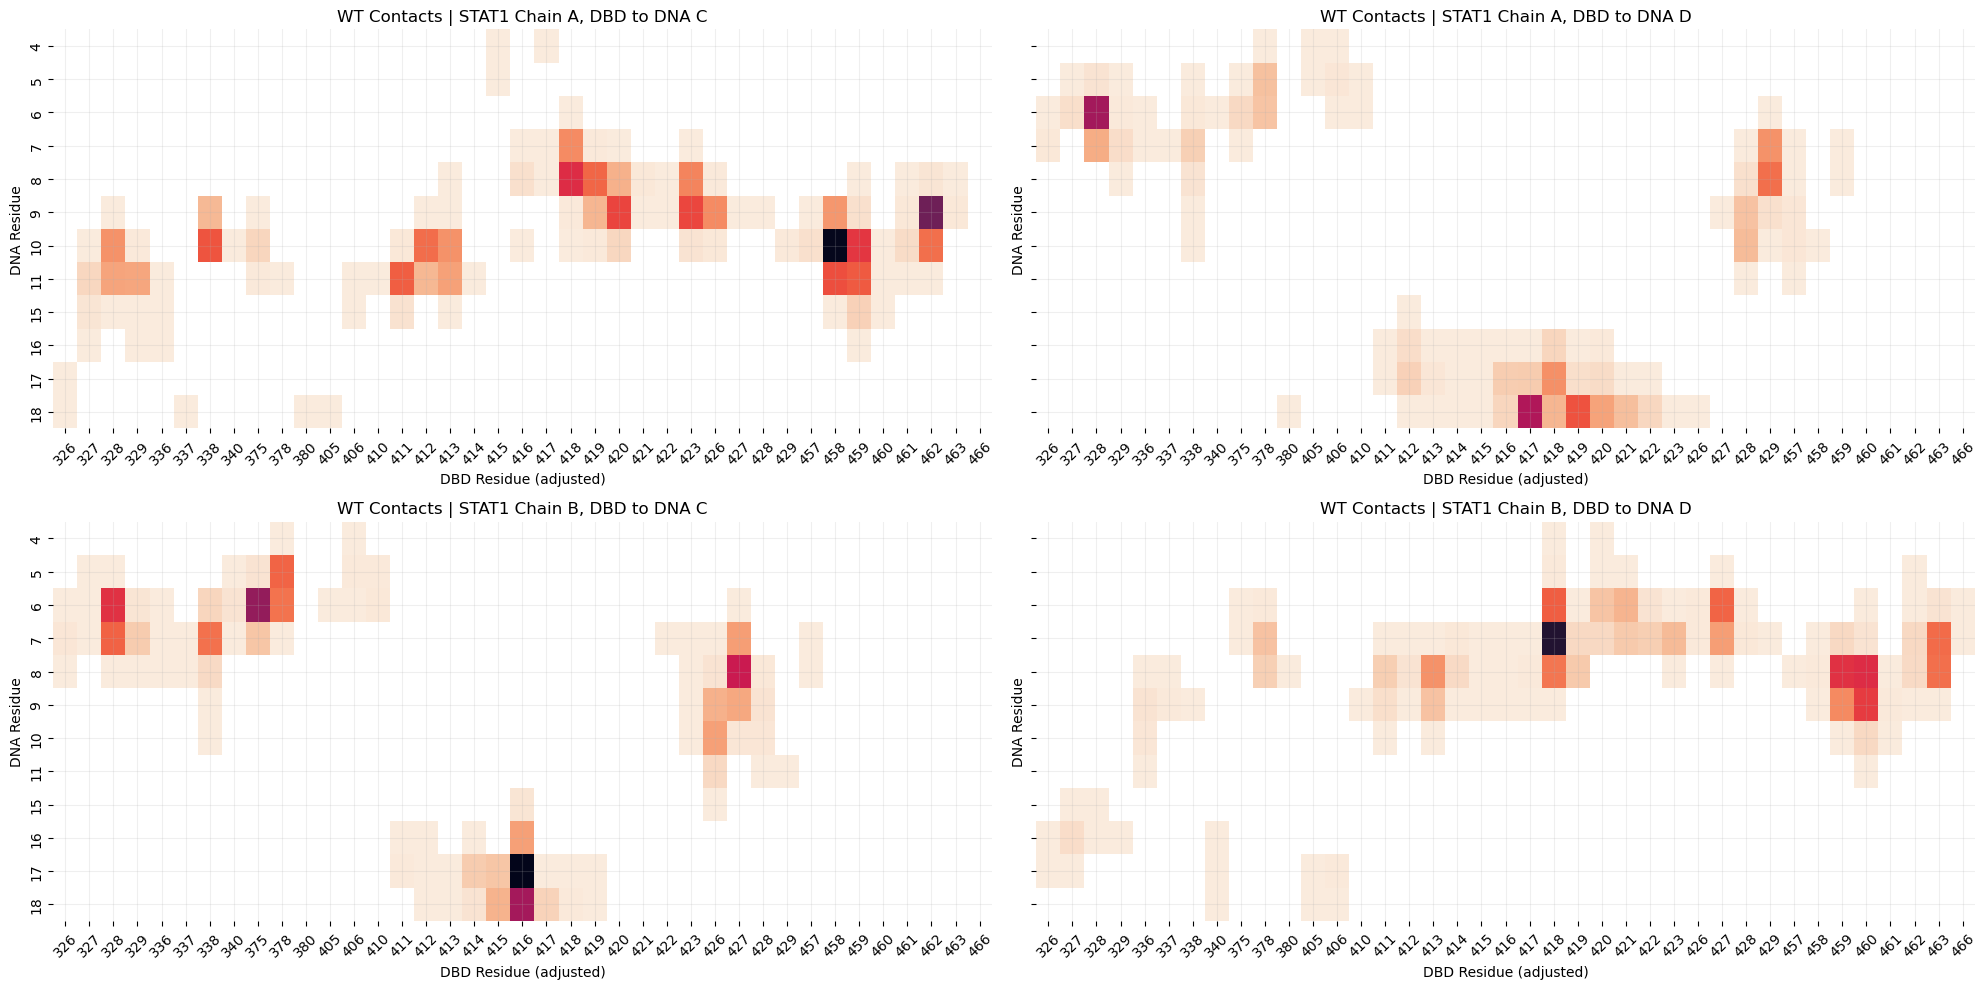

In [29]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Chain A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax2, 'WT Contacts | STAT1 Chain A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax3, 'WT Contacts | STAT1 Chain B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax4, 'WT Contacts | STAT1 Chain B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

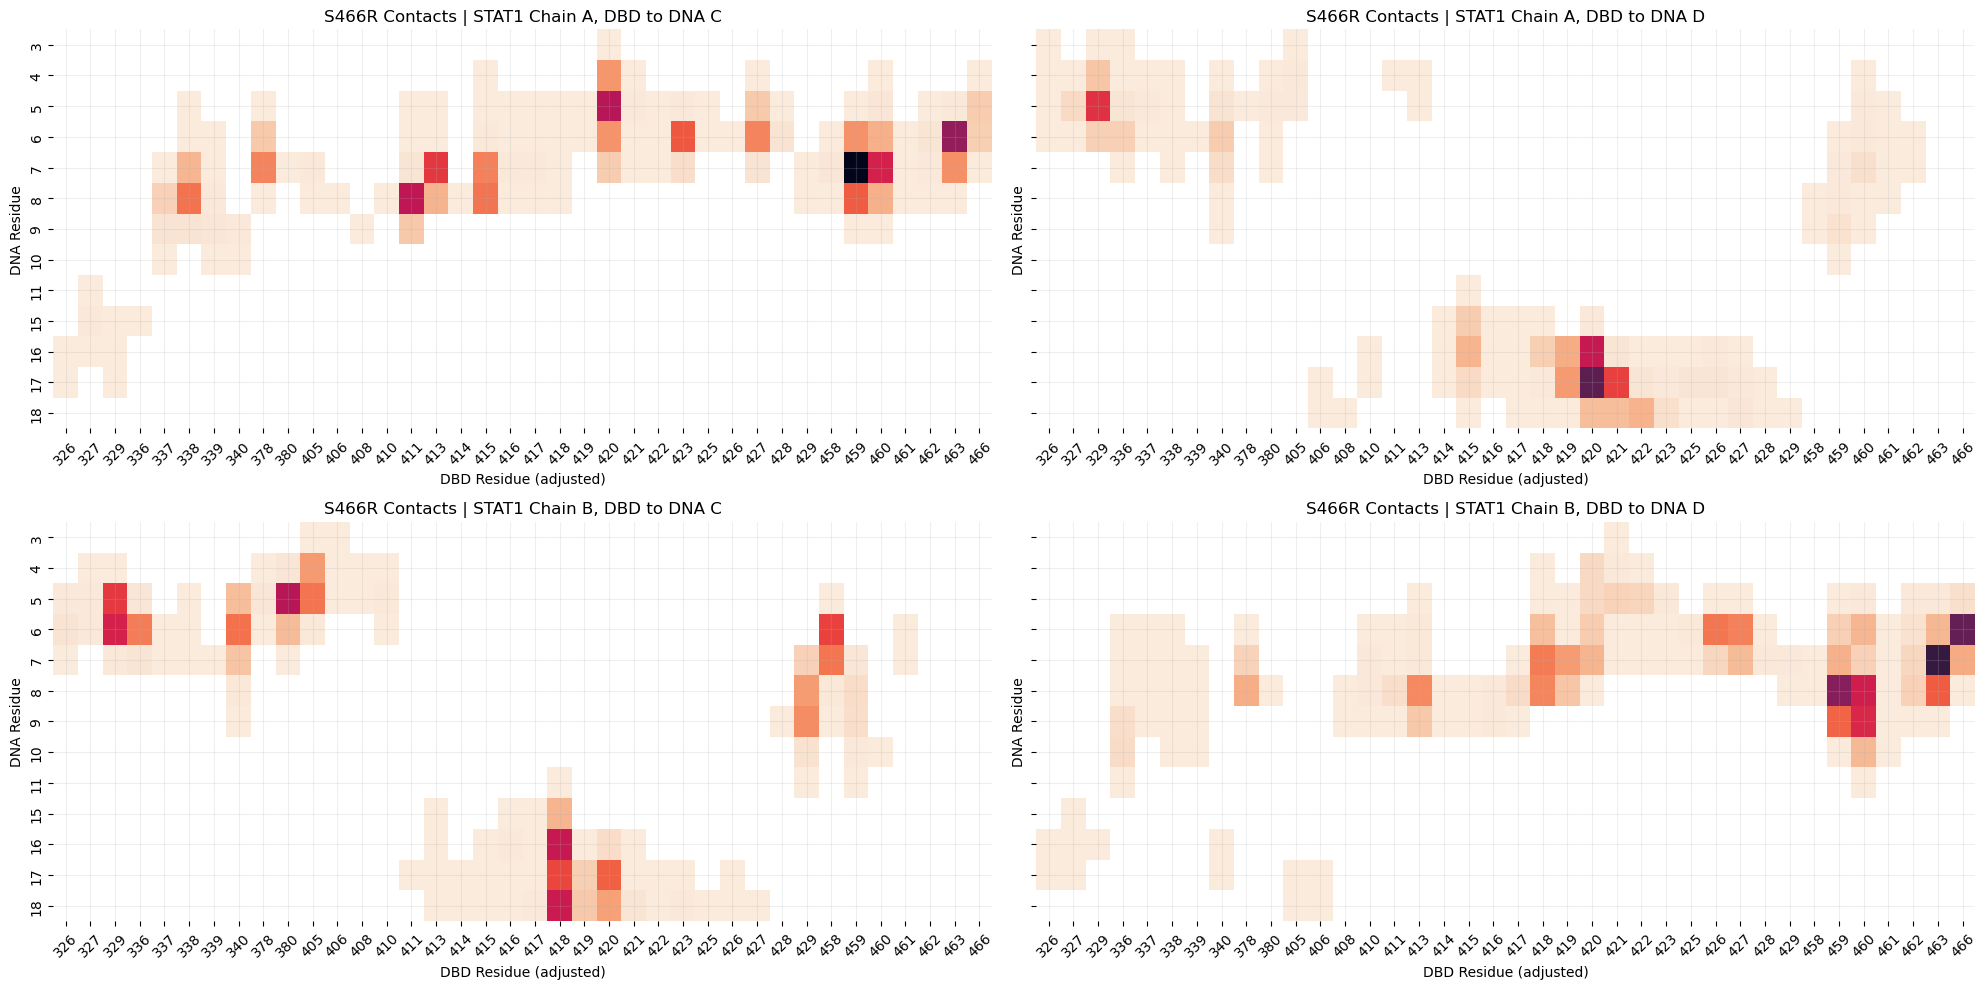

In [30]:
# Find global min and max
all_data = [
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (mut_dbd_monoA_C_pivot, ax1, 'S466R Contacts | STAT1 Chain A, DBD to DNA C'),
    (mut_dbd_monoA_D_pivot, ax2, 'S466R Contacts | STAT1 Chain A, DBD to DNA D'),
    (mut_dbd_monoB_C_pivot, ax3, 'S466R Contacts | STAT1 Chain B, DBD to DNA C'),
    (mut_dbd_monoB_D_pivot, ax4, 'S466R Contacts | STAT1 Chain B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

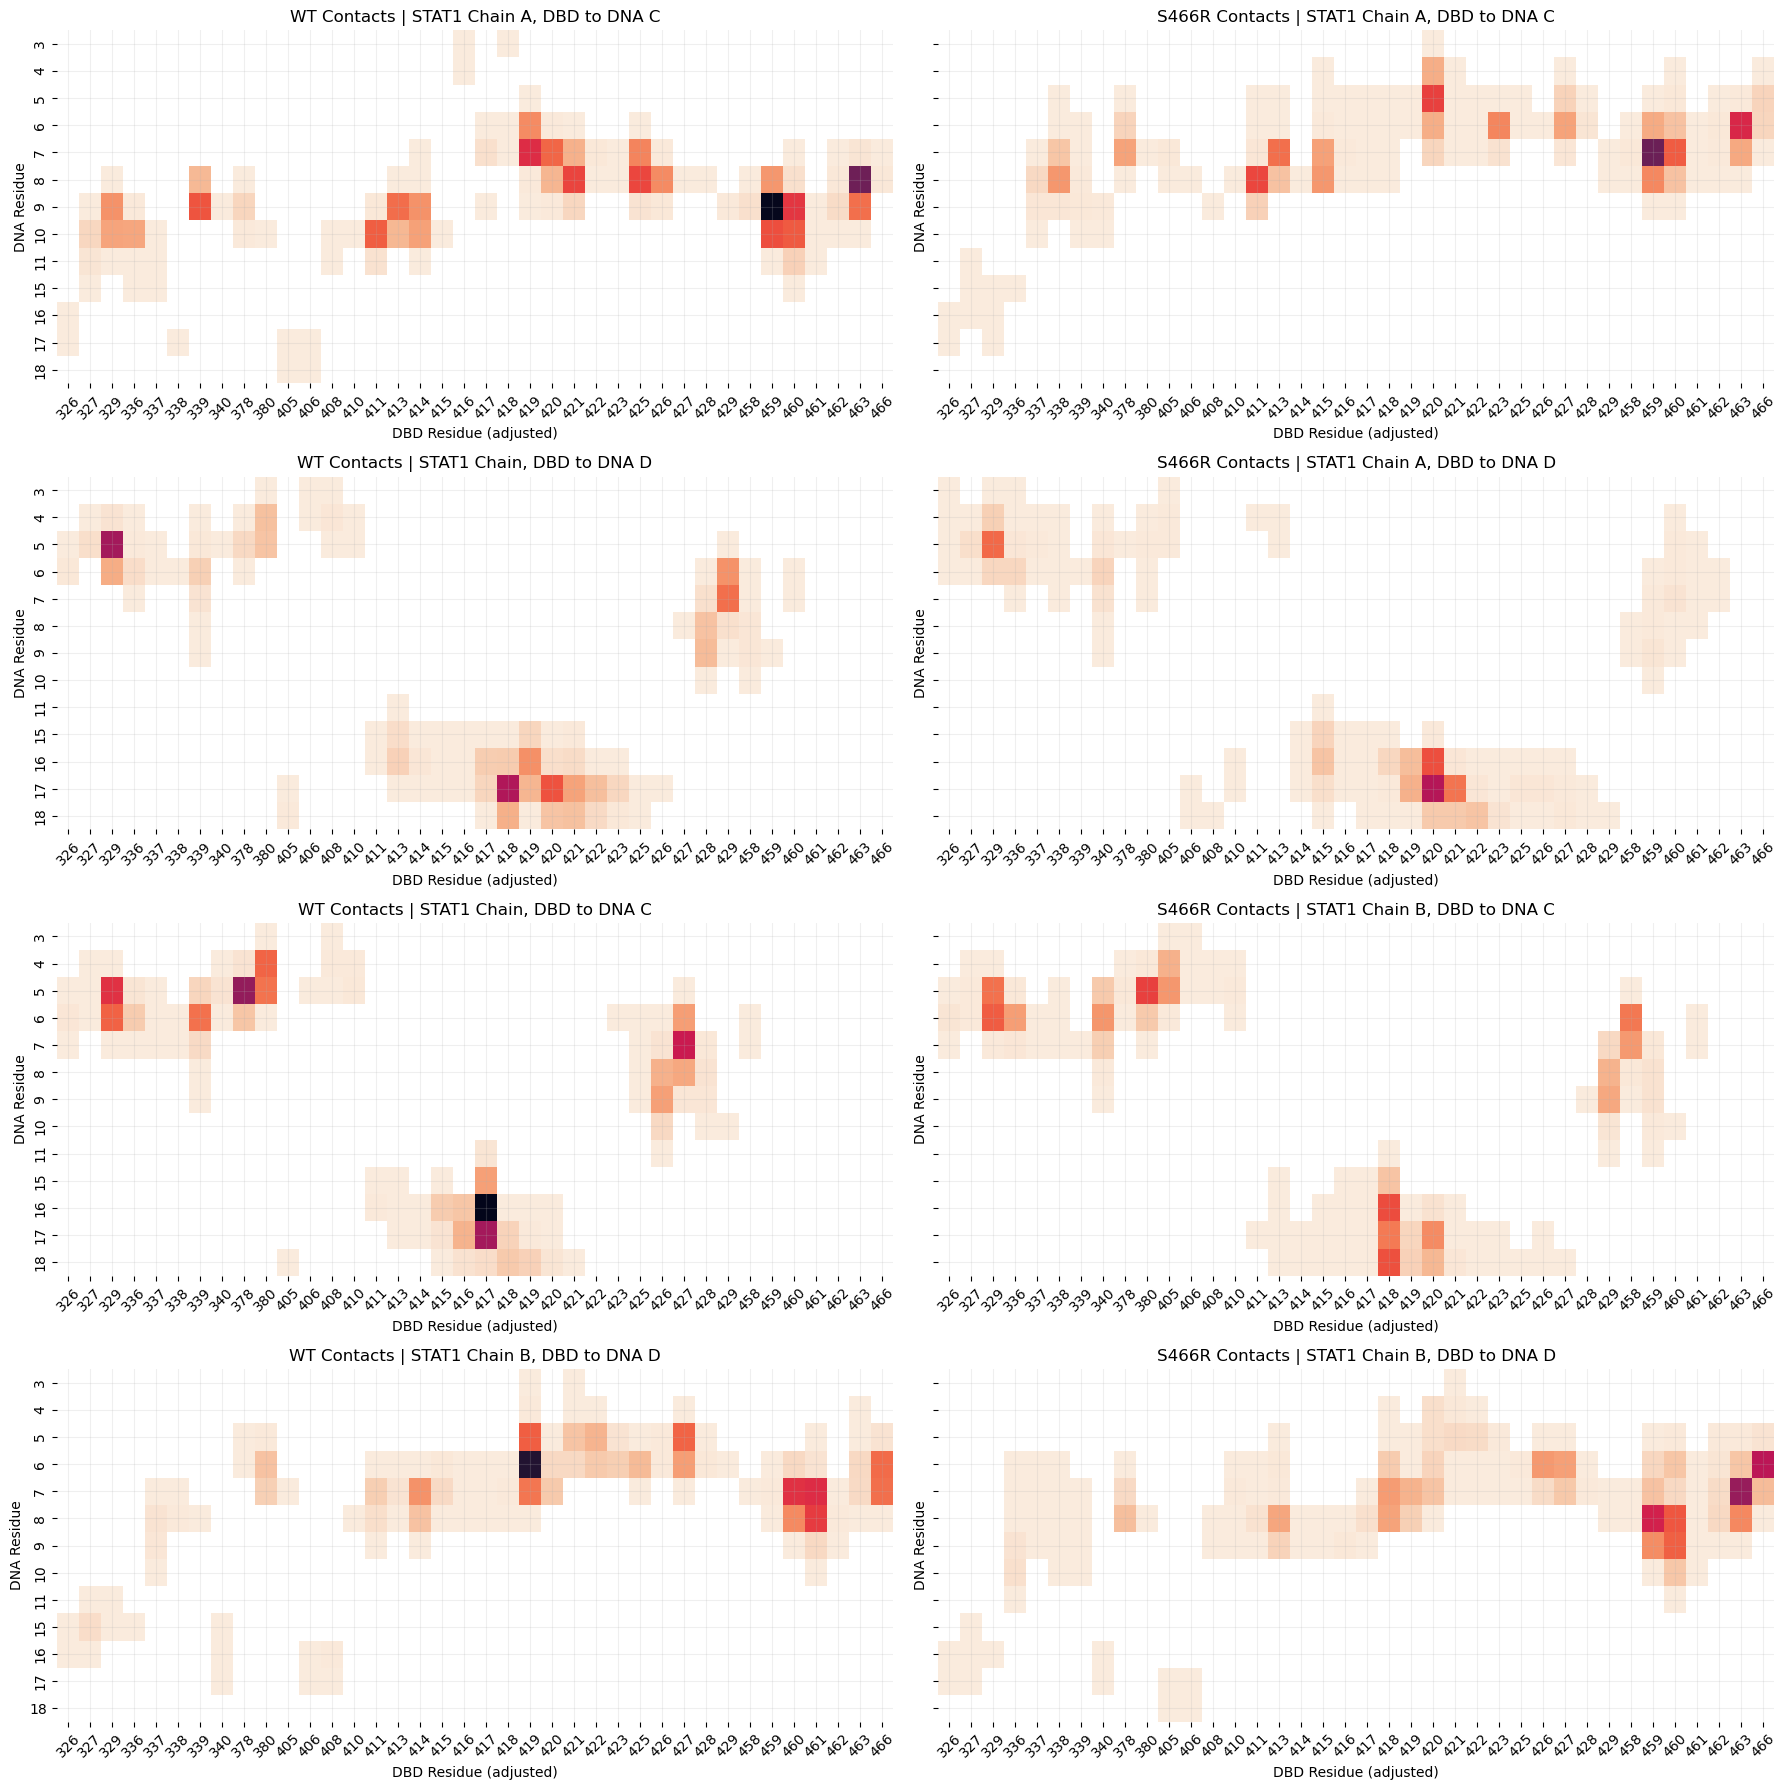

In [31]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values,
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 18), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Chain A, DBD to DNA C'),
    (mut_dbd_monoA_C_pivot, ax2, 'S466R Contacts | STAT1 Chain A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax3, 'WT Contacts | STAT1 Chain, DBD to DNA D'),
    (mut_dbd_monoA_D_pivot, ax4, 'S466R Contacts | STAT1 Chain A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax5, 'WT Contacts | STAT1 Chain, DBD to DNA C'),
    (mut_dbd_monoB_C_pivot, ax6, 'S466R Contacts | STAT1 Chain B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax7, 'WT Contacts | STAT1 Chain B, DBD to DNA D'),
    (mut_dbd_monoB_D_pivot, ax8, 'S466R Contacts | STAT1 Chain B, DBD to DNA D'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

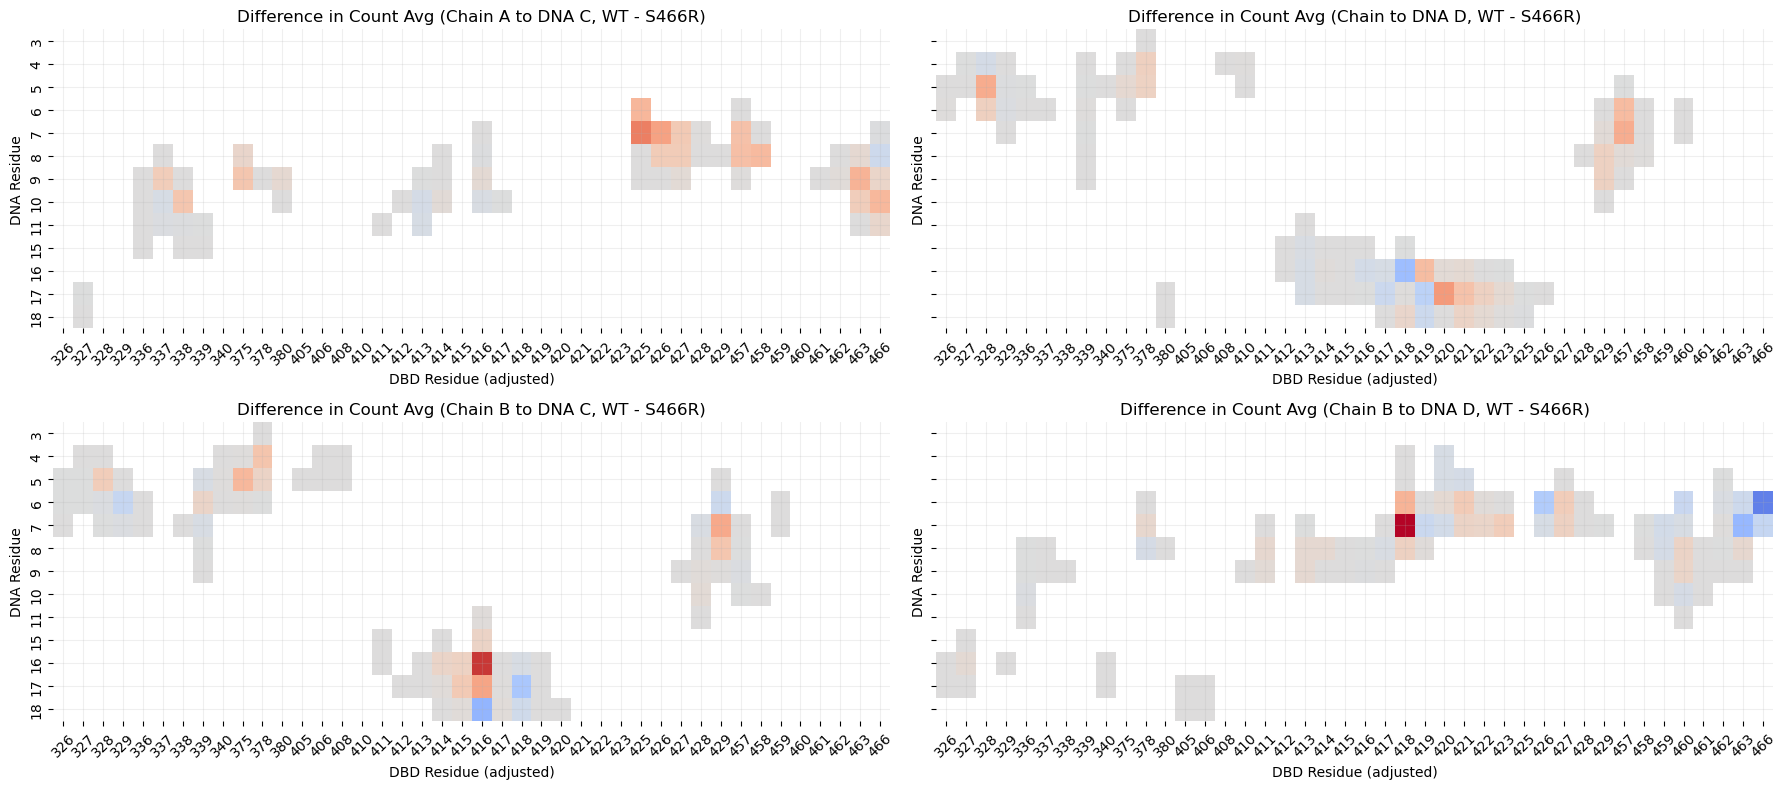

In [32]:
diff_dbd_wt_monoA_C_mut_monoA_C = wt_dbd_monoA_C_pivot - mut_dbd_monoA_C_pivot
diff_dbd_wt_monoA_D_mut_monoA_D = wt_dbd_monoA_D_pivot - mut_dbd_monoA_D_pivot
diff_dbd_wt_monoB_C_mut_monoB_C = wt_dbd_monoB_C_pivot - mut_dbd_monoB_C_pivot
diff_dbd_wt_monoB_D_mut_monoB_D = wt_dbd_monoB_D_pivot - mut_dbd_monoB_D_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_monoA_C_mut_monoA_C.values,
    diff_dbd_wt_monoA_D_mut_monoA_D.values,
    diff_dbd_wt_monoB_C_mut_monoB_C.values,
    diff_dbd_wt_monoB_D_mut_monoB_D.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (diff_dbd_wt_monoA_C_mut_monoA_C, ax1, 'Difference in Count Avg (Chain A to DNA C, WT - S466R)'),
    (diff_dbd_wt_monoA_D_mut_monoA_D, ax2, 'Difference in Count Avg (Chain to DNA D, WT - S466R)'),
    (diff_dbd_wt_monoB_C_mut_monoB_C, ax3, 'Difference in Count Avg (Chain B to DNA C, WT - S466R)'),
    (diff_dbd_wt_monoB_D_mut_monoB_D, ax4, 'Difference in Count Avg (Chain B to DNA D, WT - S466R)'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='coolwarm', 
        ax=ax, 
        cbar=False, 
        center=0,
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

#### Filter out (potential) hydrogen bonds

A separate analysis focuses on hydrogen bonds, with a distance threshold of < 3.5 Å. Applying a distance filter removes these from the contact results.

In [33]:
def aggregate_pairs_filter(df_list):
    combined = pd.concat(df_list)
    combined = combined[combined['distance'] > 3.5]
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 
                               'sele2_resnm', 'sele2_resid_adj']).size().reset_index(name='count')
    
    return agg_df

In [34]:
wt_dbd_agg_filtered = aggregate_pairs_filter(wt_dbd_dfs)
S466R_dbd_agg_filtered = aggregate_pairs_filter(S466R_dbd_dfs)

wt_dbd_agg_filtered["count_avg"] = wt_dbd_agg_filtered["count"] / (len(wt_dbd_dfs)* 1000)
S466R_dbd_agg_filtered["count_avg"] = S466R_dbd_agg_filtered["count"] / (len(S466R_dbd_dfs)* 1000)

wt_dbd_pivot_filtered = pivotdf_count_avg(wt_dbd_agg_filtered)
mut_dbd_pivot_filtered = pivotdf_count_avg(S466R_dbd_agg_filtered)

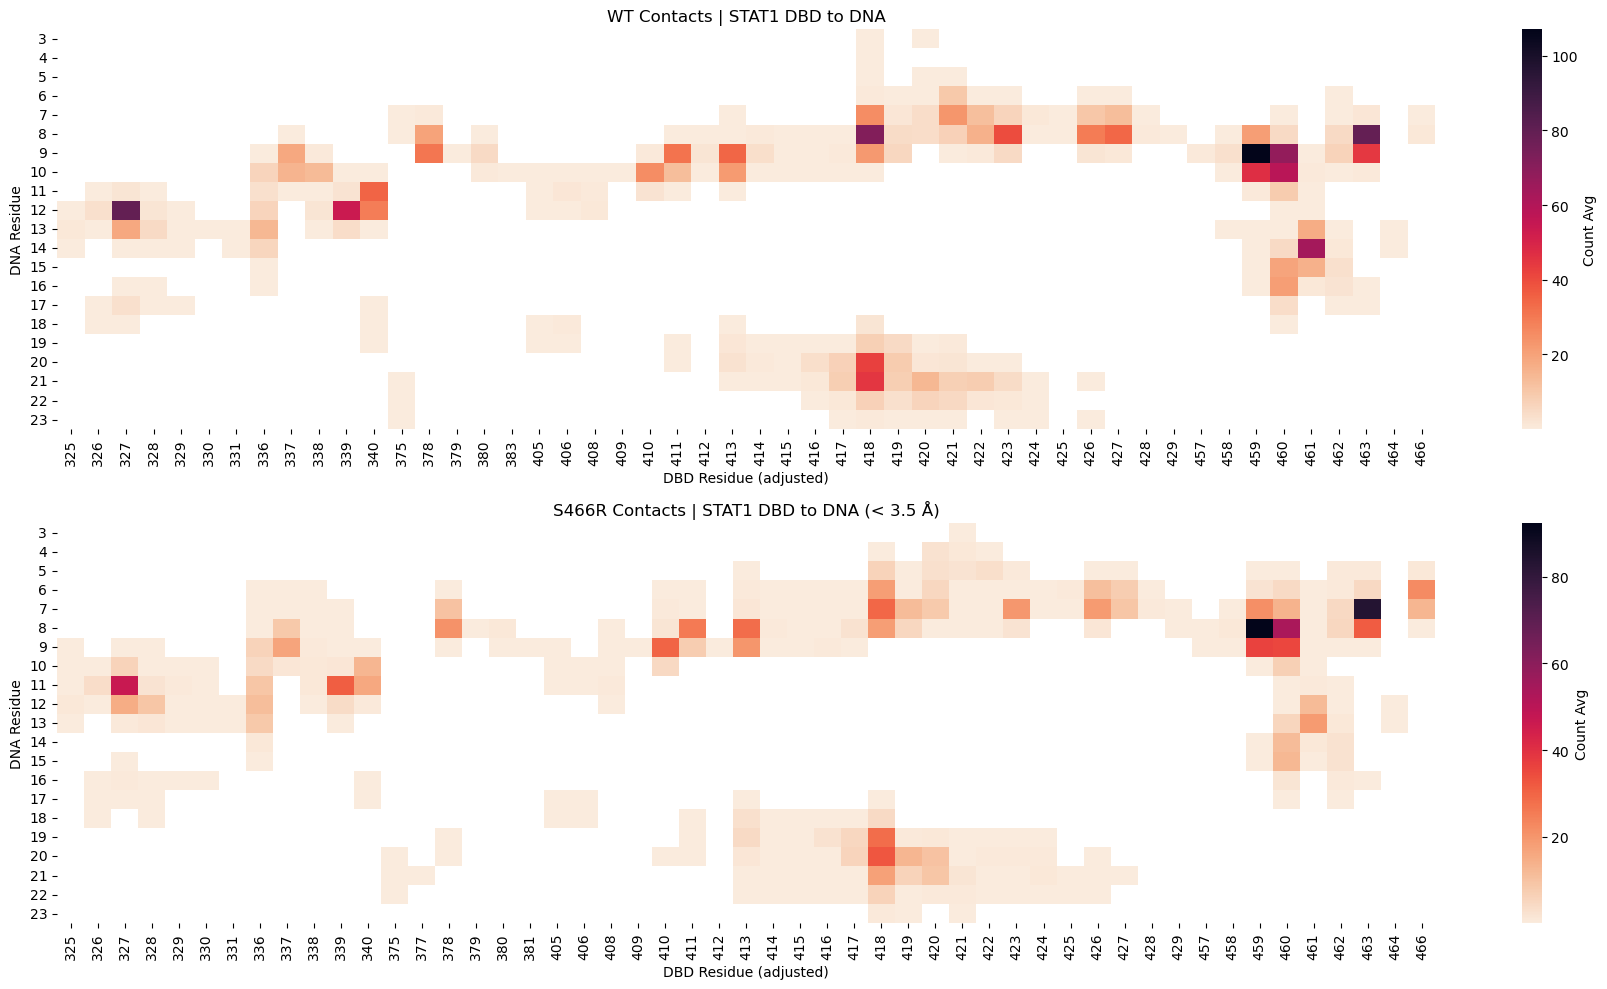

In [35]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot_filtered, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# S466R heatmap
sns.heatmap(mut_dbd_pivot_filtered, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('S466R Contacts | STAT1 DBD to DNA (< 3.5 Å)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

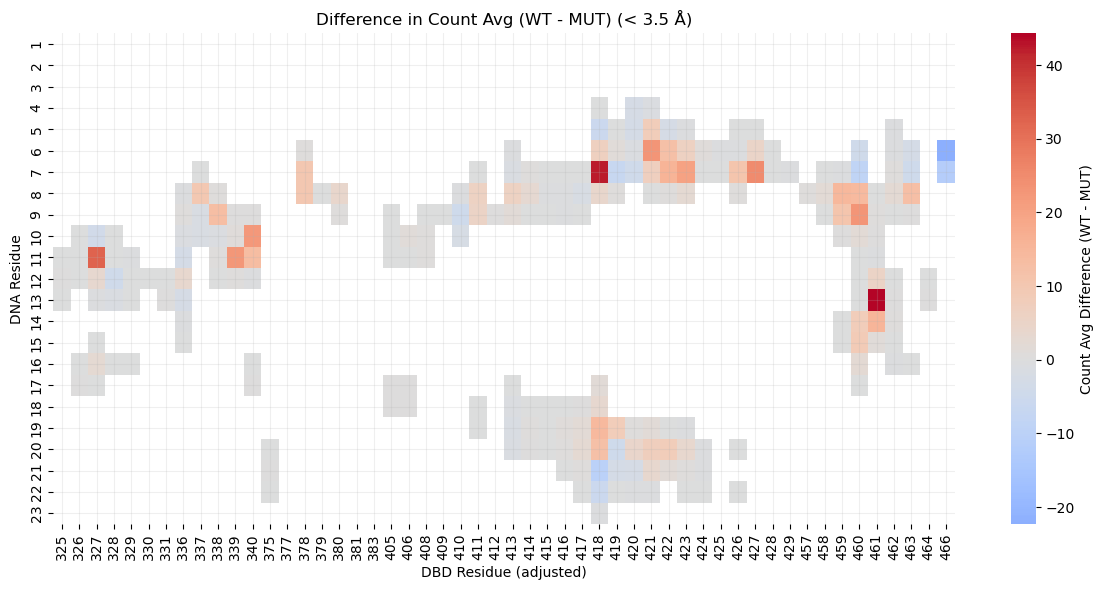

In [36]:
diff_dbd_pivot_filtered = wt_dbd_pivot_filtered - mut_dbd_pivot_filtered

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot_filtered, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT) (< 3.5 Å)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

## Full protein with DNA

### Load data

In [37]:
wt_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004_contacts/pairs_full.csv')
    wt_full_dfs.append(df)

S466R_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/004_contacts/pairs_full.csv')
    S466R_full_dfs.append(df)

In [38]:
wt_full_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,190,MET,A,12,DG,D,4.907506
1,1000,190,MET,A,12,DG,D,4.486903
2,1000,192,THR,A,12,DG,D,4.632156
3,1000,192,THR,A,11,DC,D,4.287577
4,1000,192,THR,A,11,DC,D,4.939452


### Preprocessing

Adjust residue numbers.

In [39]:
adjust_resid(wt_full_dfs + S466R_full_dfs)

In [40]:
wt_full_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,190,MET,A,12,DG,D,4.907506,325,12
1,1000,190,MET,A,12,DG,D,4.486903,325,12
2,1000,192,THR,A,12,DG,D,4.632156,327,12
3,1000,192,THR,A,11,DC,D,4.287577,327,11
4,1000,192,THR,A,11,DC,D,4.939452,327,11


In [41]:
wt_full_agg = aggregate_pairs(wt_full_dfs)
S466R_full_agg = aggregate_pairs(S466R_full_dfs)

In [42]:
wt_full_agg.sort_values('count', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg
39,ARG,418,B,DG,19,C,283033,4.145784
393,SER,459,A,DT,8,C,278783,4.098669
41,ARG,418,B,DT,7,D,257178,4.160853
137,GLN,463,A,DT,7,C,202698,4.101309
486,VAL,339,B,DC,11,C,178984,4.136174
432,THR,327,A,DC,11,D,168211,4.138601
37,ARG,418,B,DC,20,C,167178,4.146232
29,ARG,418,A,DG,20,D,159261,4.104046
510,VAL,461,B,DG,13,C,142352,4.174150
103,ASN,460,B,DT,8,D,125384,4.173410


In [43]:
wt_full_agg["count_avg"] = wt_full_agg["count"] / (len(wt_full_dfs)* 1000)
S466R_full_agg["count_avg"] = S466R_full_agg["count"] / (len(S466R_full_dfs)* 1000)

In [44]:
wt_full_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
39,ARG,418,B,DG,19,C,283033,4.145784,94.344333
393,SER,459,A,DT,8,C,278783,4.098669,92.927667
41,ARG,418,B,DT,7,D,257178,4.160853,85.726000
137,GLN,463,A,DT,7,C,202698,4.101309,67.566000
486,VAL,339,B,DC,11,C,178984,4.136174,59.661333
432,THR,327,A,DC,11,D,168211,4.138601,56.070333
37,ARG,418,B,DC,20,C,167178,4.146232,55.726000
29,ARG,418,A,DG,20,D,159261,4.104046,53.087000
510,VAL,461,B,DG,13,C,142352,4.174150,47.450667
103,ASN,460,B,DT,8,D,125384,4.173410,41.794667


In [45]:
S466R_full_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
484,SER,459,A,DT,8,C,205346,4.088663,68.448667
166,GLN,463,B,DT,7,D,175829,4.143801,58.609667
40,ARG,418,A,DG,20,D,156227,4.141812,52.075667
62,ARG,466,B,DA,6,D,151940,4.051493,50.646667
491,SER,459,B,DT,8,D,135910,4.188848,45.303333
160,GLN,463,A,DT,7,C,129901,4.144781,43.300333
39,ARG,418,A,DG,6,C,112648,4.125752,37.549333
586,VAL,339,B,DC,11,C,112446,4.118608,37.482000
337,LYS,410,A,DT,9,C,108447,4.154764,36.149000
53,ARG,418,B,DG,19,C,105074,4.092648,35.024667


In [46]:
S466R_full_agg[(S466R_full_agg['sele1_resid_adj'] == 466) & (S466R_full_agg['sele2_resid_adj'] == 7)].sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
64,ARG,466,B,DT,7,D,34317,4.089629,11.439
60,ARG,466,A,DT,7,C,15792,3.928020,5.264


In [47]:
wt_full_agg[(wt_full_agg['sele1_resid_adj'] == 466) & (wt_full_agg['sele2_resid_adj'] == 7)].sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,distance_avg,count_avg
422,SER,466,A,DT,7,C,2699,4.580714,0.899667
424,SER,466,B,DT,7,D,33,4.750930,0.011000


### Comparison

#### By average count

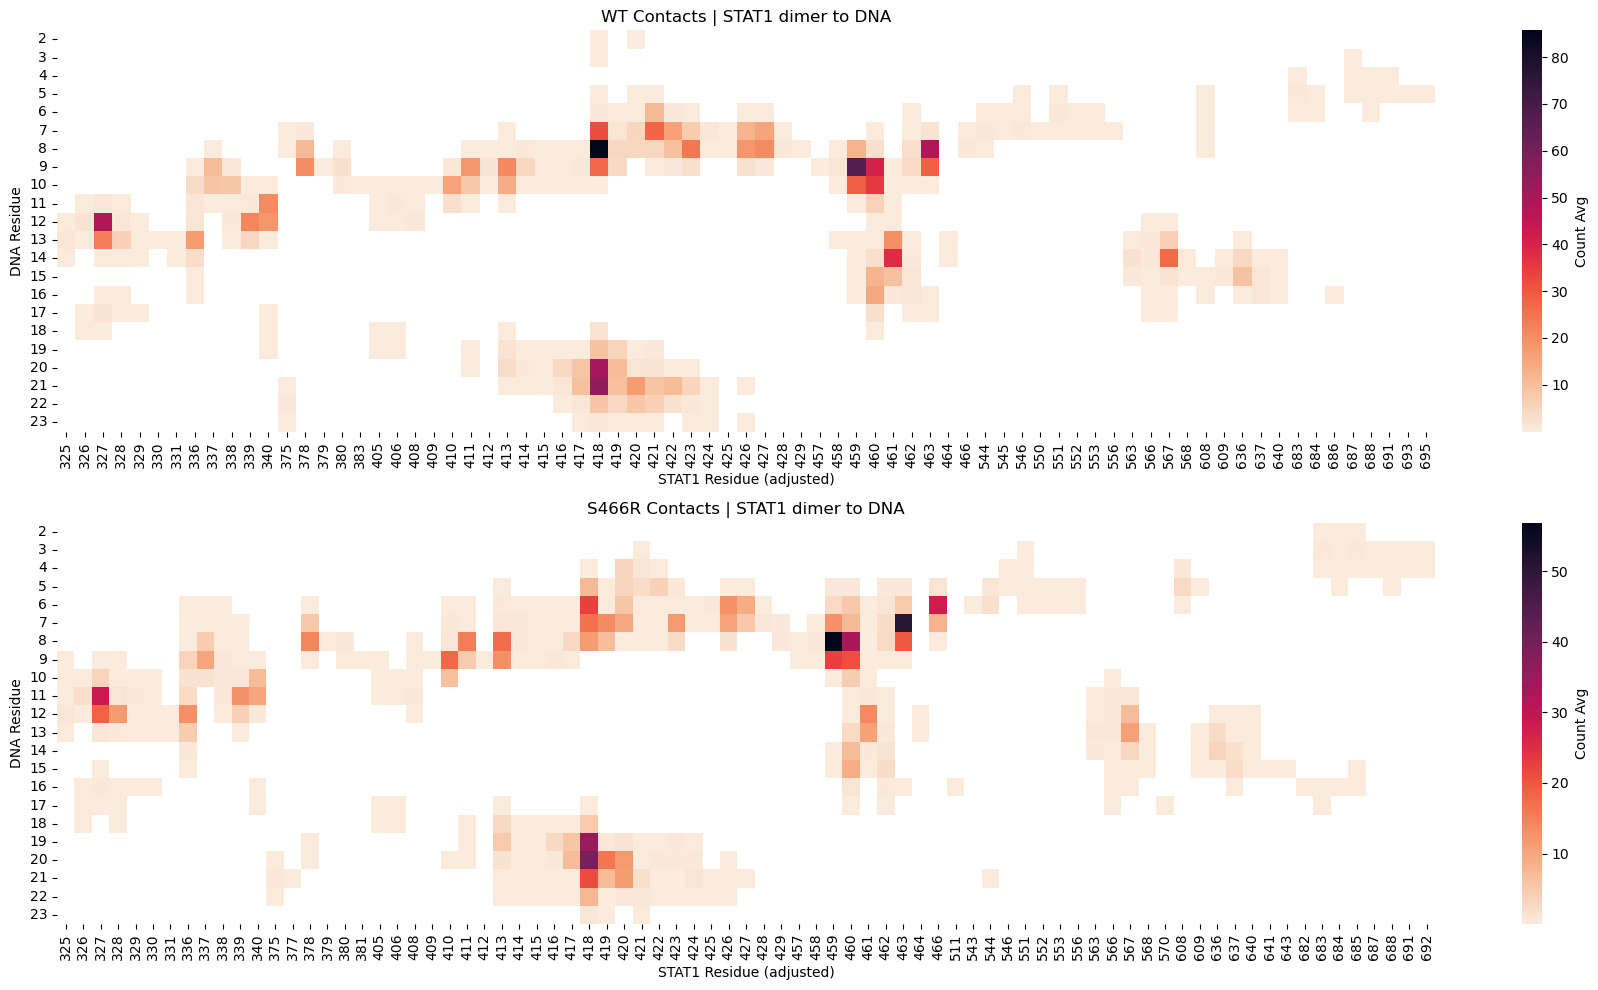

In [48]:
wt_full_pivot = pivotdf_count_avg(wt_full_agg)
mut_full_pivot = pivotdf_count_avg(S466R_full_agg)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_full_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 dimer to DNA')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# S466R heatmap
sns.heatmap(mut_full_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('S466R Contacts | STAT1 dimer to DNA')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

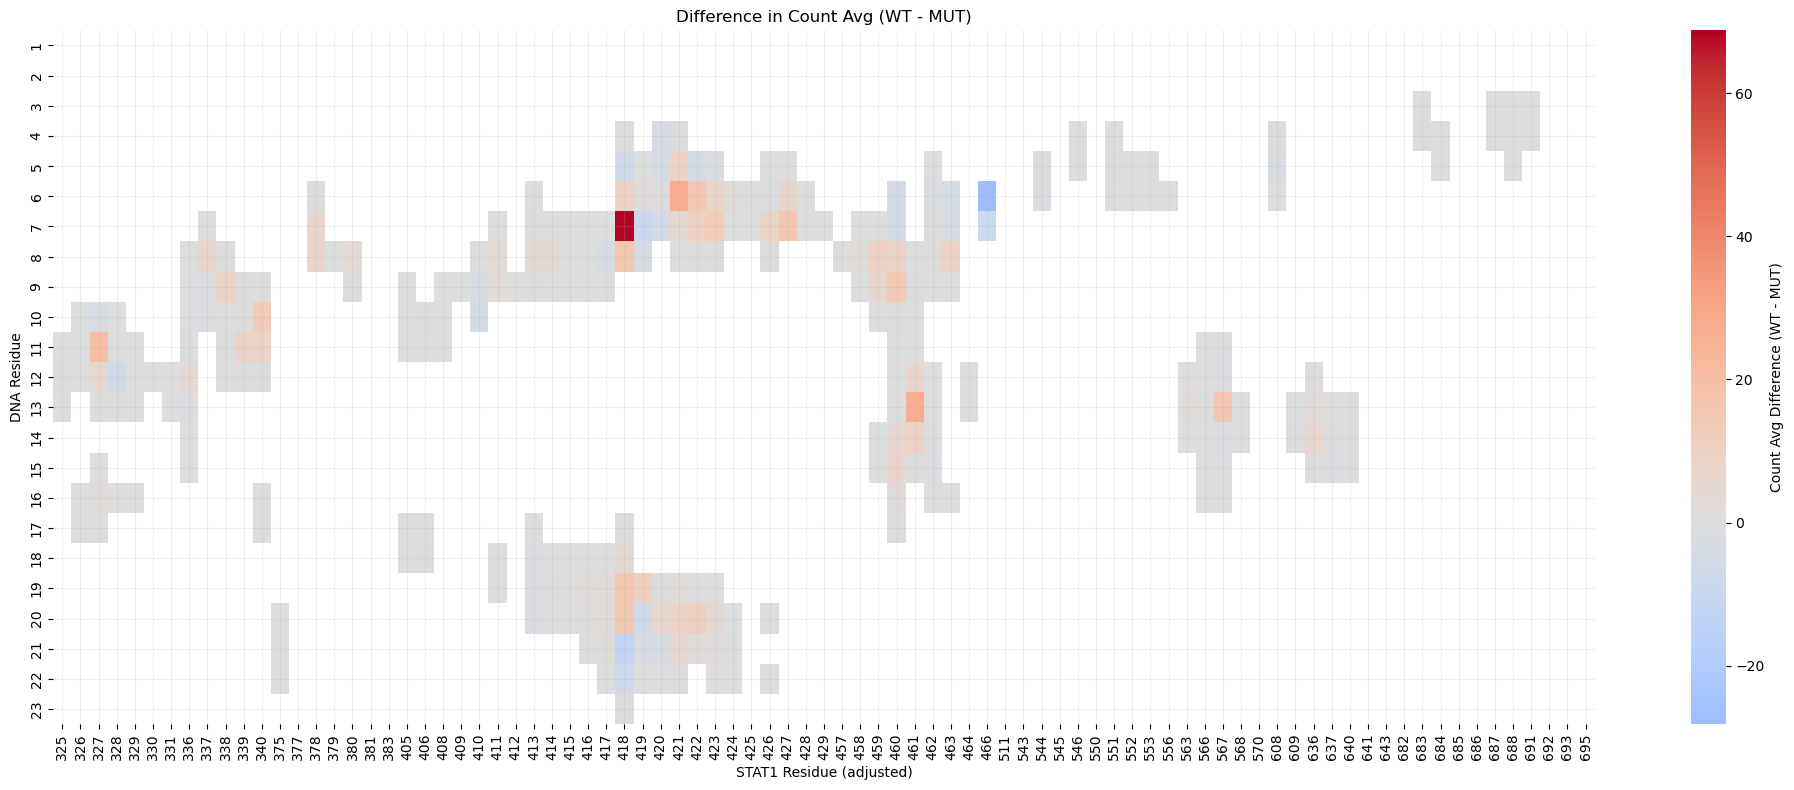

In [49]:
diff_full_pivot = wt_full_pivot - mut_full_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_full_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By average distance

In [50]:
def pivotdf_distance_avg(df):
    pivot = df.pivot_table(values='distance_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

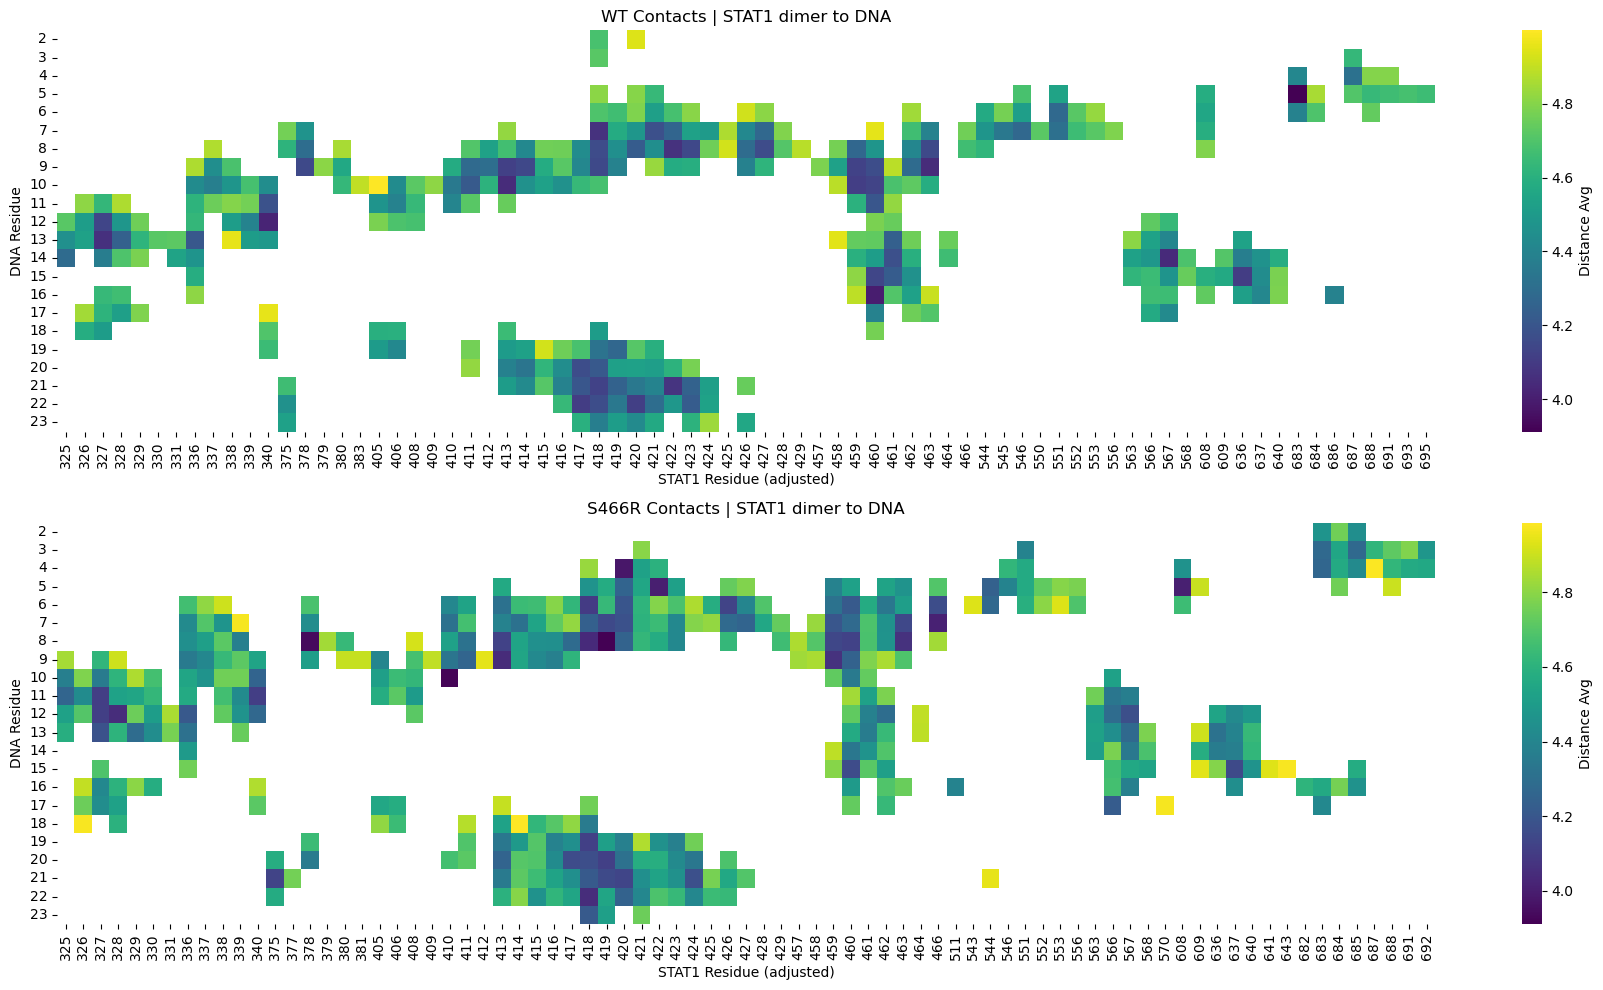

In [51]:
wt_full_pivot = pivotdf_distance_avg(wt_full_agg)
mut_full_pivot = pivotdf_distance_avg(S466R_full_agg)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_full_pivot, cmap='viridis', ax=ax1, cbar_kws={'label': 'Distance Avg'})
ax1.set_title('WT Contacts | STAT1 dimer to DNA')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# S466R heatmap
sns.heatmap(mut_full_pivot, cmap='viridis', ax=ax2, cbar_kws={'label': 'Distance Avg'})
ax2.set_title('S466R Contacts | STAT1 dimer to DNA')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

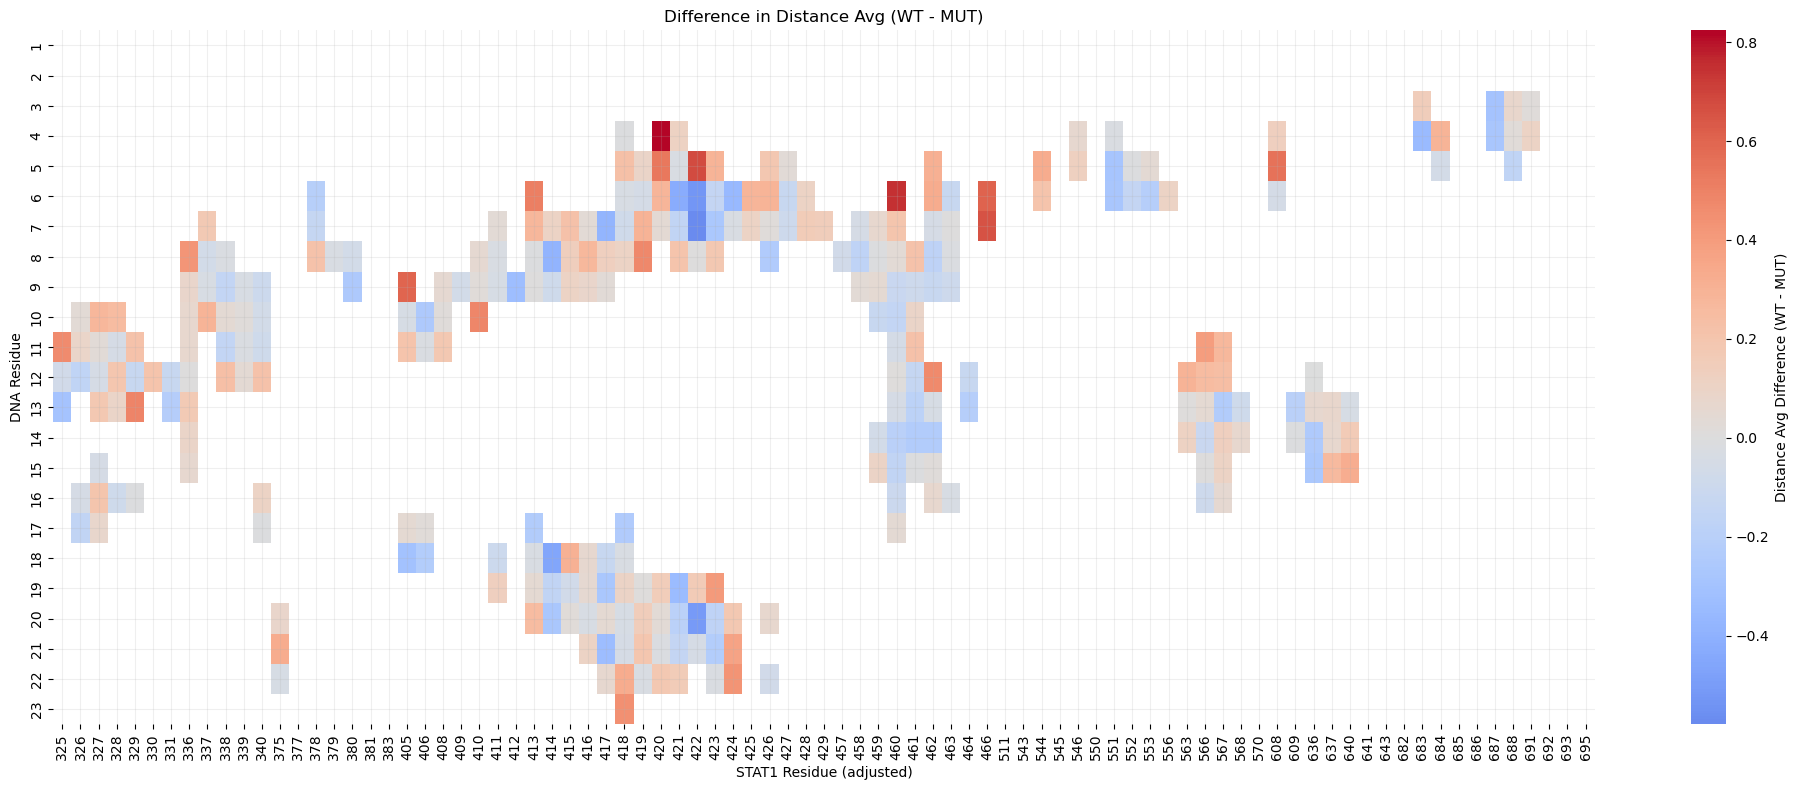

In [52]:
diff_full_pivot = wt_full_pivot - mut_full_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_full_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Distance Avg Difference (WT - MUT)'})
plt.title('Difference in Distance Avg (WT - MUT)')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

In [53]:
wt_full_agg_monoA_C = wt_full_agg[(wt_full_agg['sele1_chain'] == 'A') & (wt_full_agg['sele2_chain'] == 'C')]
wt_full_agg_monoA_D = wt_full_agg[(wt_full_agg['sele1_chain'] == 'A') & (wt_full_agg['sele2_chain'] == 'D')]
wt_full_agg_monoB_C = wt_full_agg[(wt_full_agg['sele1_chain'] == 'B') & (wt_full_agg['sele2_chain'] == 'C')]
wt_full_agg_monoB_D = wt_full_agg[(wt_full_agg['sele1_chain'] == 'B') & (wt_full_agg['sele2_chain'] == 'D')]

wt_full_monoA_C_pivot = pivotdf_distance_avg(wt_full_agg_monoA_C)
wt_full_monoA_D_pivot = pivotdf_distance_avg(wt_full_agg_monoA_D)
wt_full_monoB_C_pivot = pivotdf_distance_avg(wt_full_agg_monoB_C)
wt_full_monoB_D_pivot = pivotdf_distance_avg(wt_full_agg_monoB_D)

S466R_full_agg_monoA_C = S466R_full_agg[(S466R_full_agg['sele1_chain'] == 'A') & (S466R_full_agg['sele2_chain'] == 'C')]
S466R_full_agg_monoA_D = S466R_full_agg[(S466R_full_agg['sele1_chain'] == 'A') & (S466R_full_agg['sele2_chain'] == 'D')]
S466R_full_agg_monoB_C = S466R_full_agg[(S466R_full_agg['sele1_chain'] == 'B') & (S466R_full_agg['sele2_chain'] == 'C')]
S466R_full_agg_monoB_D = S466R_full_agg[(S466R_full_agg['sele1_chain'] == 'B') & (S466R_full_agg['sele2_chain'] == 'D')]

mut_full_monoA_C_pivot = pivotdf_distance_avg(S466R_full_agg_monoA_C)
mut_full_monoA_D_pivot = pivotdf_distance_avg(S466R_full_agg_monoA_D)
mut_full_monoB_C_pivot = pivotdf_distance_avg(S466R_full_agg_monoB_C)
mut_full_monoB_D_pivot = pivotdf_distance_avg(S466R_full_agg_monoB_D)

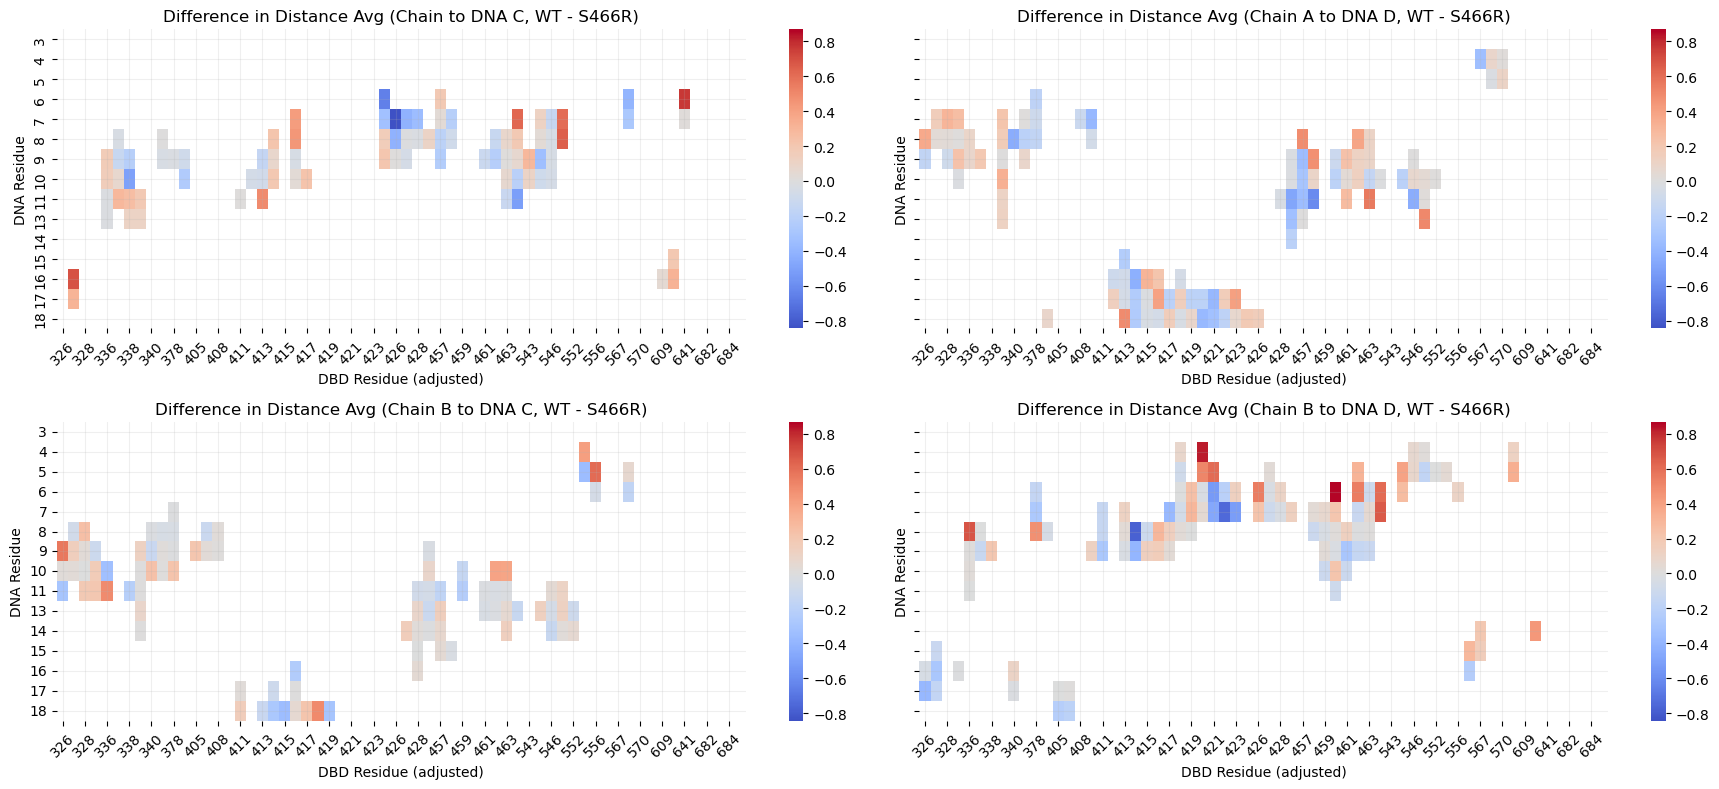

In [54]:
diff_full_wt_monoA_C_mut_monoA_C = wt_full_monoA_C_pivot - mut_full_monoA_C_pivot
diff_full_wt_monoA_D_mut_monoA_D = wt_full_monoA_D_pivot - mut_full_monoA_D_pivot
diff_full_wt_monoB_C_mut_monoB_C = wt_full_monoB_C_pivot - mut_full_monoB_C_pivot
diff_full_wt_monoB_D_mut_monoB_D = wt_full_monoB_D_pivot - mut_full_monoB_D_pivot

# Find global min and max
all_data = [
    diff_full_wt_monoA_C_mut_monoA_C.values,
    diff_full_wt_monoA_D_mut_monoA_D.values,
    diff_full_wt_monoB_C_mut_monoB_C.values,
    diff_full_wt_monoB_D_mut_monoB_D.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (diff_full_wt_monoA_C_mut_monoA_C, ax1, 'Difference in Distance Avg (Chain to DNA C, WT - S466R)'),
    (diff_full_wt_monoA_D_mut_monoA_D, ax2, 'Difference in Distance Avg (Chain A to DNA D, WT - S466R)'),
    (diff_full_wt_monoB_C_mut_monoB_C, ax3, 'Difference in Distance Avg (Chain B to DNA C, WT - S466R)'),
    (diff_full_wt_monoB_D_mut_monoB_D, ax4, 'Difference in Distance Avg (Chain B to DNA D, WT - S466R)'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='coolwarm', 
        ax=ax, 
        cbar=True, 
        center=0,
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

#### Statistical significance (Mann-Whitney U)

In [55]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf
import os

In [56]:
wt_data = pd.concat(wt_full_dfs, ignore_index=True)
S466R_data = pd.concat(S466R_full_dfs, ignore_index=True)

In [57]:
# Define residue pair identifier
def create_pair_id(row):
    return f"{row['sele1_resid']}_{row['sele1_chain']}-{row['sele2_resid']}_{row['sele2_chain']}"

Mann-Whitney U test

In [58]:
wt_data['pair_id'] = wt_data.apply(create_pair_id, axis=1)
S466R_data['pair_id'] = S466R_data.apply(create_pair_id, axis=1)

# Get unique residue pairs present in either condition
all_pairs = set(wt_data['pair_id']).union(set(S466R_data['pair_id']))

# Store results
results = []

# Perform Mann-Whitney U test for each residue pair
for pair in all_pairs:
    # Extract distances for this pair in each condition
    dist_wt = wt_data[wt_data['pair_id'] == pair]['distance'].values
    dist_S466R = S466R_data[S466R_data['pair_id'] == pair]['distance'].values
    
    # Skip if either condition has no data or insufficient data
    if len(dist_wt) < 2 or len(dist_S466R) < 2:
        continue
    
    # Perform Mann-Whitney U test
    stat, p_value = mannwhitneyu(dist_wt, dist_S466R, alternative='two-sided')
    
    # Store result
    sele1, sele2 = pair.split('-')
    sele1_resid, sele1_chain = sele1.split('_')
    sele2_resid, sele2_chain = sele2.split('_')
    results.append({
        'pair': pair,
        'sele1': sele1,
        'sele2': sele2,
        'sele1_resid': int(sele1_resid) + 135,
        'sele1_chain': sele1_chain,
        'sele2_resid': int(sele2_resid),
        'sele2_chain': sele2_chain,
        'u_statistic': stat,
        'p_value': p_value,
        'n_cond1': len(dist_wt),
        'n_cond2': len(dist_S466R)
    })

# Convert results to dataframe
mannwhitney_df = pd.DataFrame(results)

In [59]:
mannwhitney_df[['pair', 'n_cond1', 'n_cond2']].sort_values(['n_cond1', 'n_cond2'], ascending=False).head(10)

,pair,n_cond1,n_cond2
274,283_B-19_C,283033,105074
240,324_A-8_C,278783,205346
205,283_B-7_D,257178,56639
294,328_A-7_C,202698,129901
293,204_B-11_C,178984,112446
300,192_A-11_D,168211,88630
345,283_B-20_C,167178,78961
251,283_A-20_D,159261,156227
258,326_B-13_C,142352,58960
99,325_B-8_D,125384,99966


Check ACF correlation score between timeframes

In [60]:
# Parameters
lags = 50  # Maximum lags for ACF computation
acf_threshold = 0.1  # Threshold for significant autocorrelation
output_dir = "acf_analysis"
os.makedirs(output_dir, exist_ok=True)

# Get unique residue pairs
unique_pairs = wt_data['pair_id'].unique()

# Initialize results list
results_acf = []

# Compute ACF metrics for each pair
for pair_id in unique_pairs:
    # Extract distance data
    pair_data = wt_data[wt_data['pair_id'] == pair_id]['distance'].dropna()
    
    # Skip if insufficient data
    if len(pair_data) < 2:
        print(f"Skipping pair {pair_id}: insufficient data ({len(pair_data)} points)")
        continue
    
    # Compute ACF
    try:
        acf_values = acf(pair_data, nlags=min(lags, len(pair_data)-1), fft=True)
    except Exception as e:
        print(f"Error computing ACF for pair {pair_id}: {e}")
        continue
    
    # Metric 1: Lag where ACF drops below threshold
    significant_lags = np.where(np.abs(acf_values) < acf_threshold)[0]
    lag_to_threshold = significant_lags[0] if len(significant_lags) > 0 else len(acf_values)
    
    # Metric 2: Sum of absolute ACF values (excluding lag 0)
    sum_abs_acf = np.sum(np.abs(acf_values[1:]))  # Skip lag 0 (always 1)
    
    # Metric 3: Effective sample size
    # n_eff = n / (1 + 2 * sum(ACF_k for k=1 to infinity))
    sum_acf = np.sum(acf_values[1:])  # Sum positive ACF for approximation
    n = len(pair_data)
    n_eff = n / (1 + 2 * sum_acf) if (1 + 2 * sum_acf) > 0 else n
    
    # Store results
    results_acf.append({
        'pair_id': pair_id,
        'n_points': n,
        'lag_to_threshold': lag_to_threshold,
        'sum_abs_acf': sum_abs_acf,
        'n_eff': n_eff
    })

# Create results dataframe
results_acf_df = pd.DataFrame(results_acf)


Skipping pair 415_A-6_C: insufficient data (1 points)
Skipping pair 328_A-15_D: insufficient data (1 points)
Skipping pair 270_B-11_C: insufficient data (1 points)
Skipping pair 473_A-15_D: insufficient data (1 points)
Skipping pair 558_B-4_C: insufficient data (1 points)
Skipping pair 325_B-6_D: insufficient data (1 points)
Skipping pair 203_B-12_C: insufficient data (1 points)
Skipping pair 281_A-18_D: insufficient data (1 points)
Skipping pair 190_B-13_C: insufficient data (1 points)
Skipping pair 552_A-2_D: insufficient data (1 points)
Skipping pair 280_A-18_D: insufficient data (1 points)
Skipping pair 203_A-11_C: insufficient data (1 points)
Skipping pair 553_B-5_C: insufficient data (1 points)
Skipping pair 270_A-9_D: insufficient data (1 points)
Skipping pair 194_B-11_C: insufficient data (1 points)
Skipping pair 240_B-22_C: insufficient data (1 points)
Skipping pair 205_B-16_D: insufficient data (1 points)
Skipping pair 326_A-8_C: insufficient data (1 points)
Skipping pair 324

In [61]:
results_acf_df.head()

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
0,190_A-12_D,3098,1,2.244748,568.649687
1,192_A-12_D,46233,3,4.472638,5813.958897
2,192_A-11_D,168211,3,1.282405,136363.515405
3,201_A-9_C,15151,8,4.053376,1663.710519
4,201_A-10_C,5463,1,2.593215,883.061794


In [62]:

# Sort by lag_to_threshold (descending) to highlight pairs with persistent correlation
results_acf_df = results_acf_df.sort_values('lag_to_threshold', ascending=False)

# Save results to CSV
results_acf_df.to_csv(os.path.join(output_dir, 'acf_metrics.csv'), index=False)


In [63]:
# Summary statistics
print(f"Analyzed {len(results_acf_df)} residue pairs.")
print(f"Mean lag to threshold (ACF < {acf_threshold}): {results_acf_df['lag_to_threshold'].mean():.2f}")
print(f"Max lag to threshold: {results_acf_df['lag_to_threshold'].max()}")
print(f"Pairs with lag_to_threshold > 10: {len(results_acf_df[results_acf_df['lag_to_threshold'] > 10])}")
print(f"Results saved to '{output_dir}/acf_metrics.csv'")

Analyzed 495 residue pairs.
Mean lag to threshold (ACF < 0.1): 3.85
Max lag to threshold: 51
Pairs with lag_to_threshold > 10: 24
Results saved to 'acf_analysis/acf_metrics.csv'


In [64]:
results_acf_df[results_acf_df['lag_to_threshold'] > 10].sort_values('lag_to_threshold', ascending=False)

,pair_id,n_points,lag_to_threshold,sum_abs_acf,n_eff
22,283_A-19_D,23469,51,7.056713,1552.857689
131,201_A-11_D,2633,51,7.363233,167.424783
37,291_A-8_C,6392,51,9.177619,330.246516
46,325_A-7_C,8770,51,7.641818,538.577490
70,190_B-12_C,3463,51,11.843764,140.273253
244,325_B-13_C,6466,51,9.562083,321.305226
124,328_B-9_D,798,51,9.181189,41.213946
39,292_A-8_C,2897,47,7.604235,184.465431
194,327_B-13_C,2462,39,7.626463,151.480413
129,190_A-11_D,458,36,9.150621,23.729044


In [65]:
# Adjust p-values for multiple testing
# Bonferroni
mannwhitney_df['p_adjusted_bonferroni'] = multipletests(mannwhitney_df['p_value'], method='bonferroni')[1]
# Benjamini-Hochberg
mannwhitney_df['p_adjusted_bh'] = multipletests(mannwhitney_df['p_value'], method='fdr_bh')[1]

In [66]:
mannwhitney_df.head()

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
0,201_B-11_D,201_B,11_D,336,B,11,D,39338.0,7.458647e-01,141,568,1.000000e+00,8.083561e-01
1,502_B-14_C,502_B,14_C,637,B,14,C,20500954.0,1.995273e-24,4009,9202,8.001046e-22,8.248501e-24
2,291_B-6_D,291_B,6_D,426,B,6,D,57111227.0,6.132498e-231,1256,59278,2.459132e-228,1.536957e-229
3,327_A-9_C,327_A,9_C,462,A,9,C,125.0,7.216107e-01,148,2,1.000000e+00,7.863954e-01
4,201_B-11_C,201_B,11_C,336,B,11,C,221197081.0,2.538993e-91,16029,24671,1.018136e-88,2.121117e-90


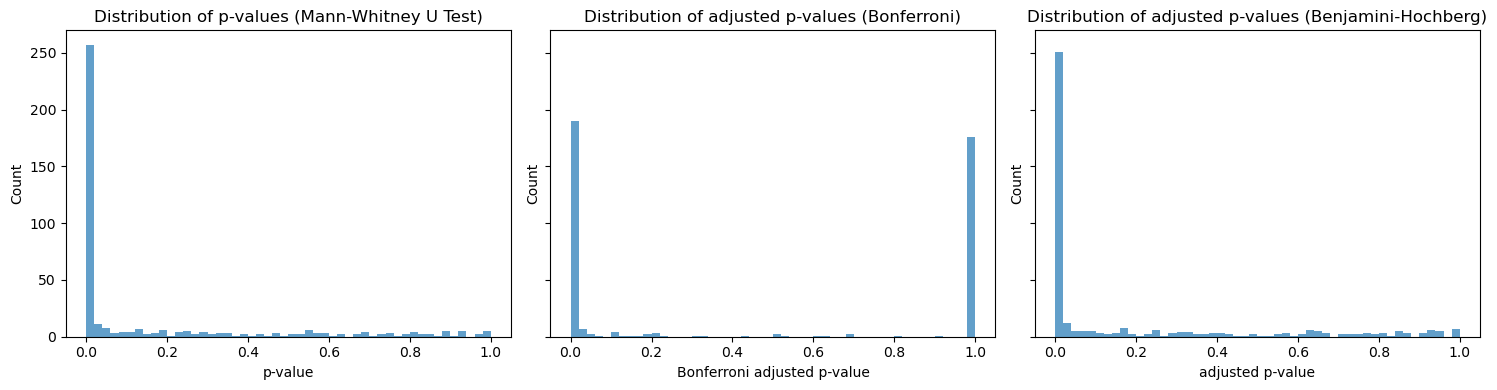

In [67]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax1.hist(mannwhitney_df['p_value'], bins=50, alpha=0.7)
ax1.set_xlabel('p-value')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of p-values (Mann-Whitney U Test)')

ax2.hist(mannwhitney_df['p_adjusted_bonferroni'], bins=50, alpha=0.7)
ax2.set_xlabel('Bonferroni adjusted p-value')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of adjusted p-values (Bonferroni)')

ax3.hist(mannwhitney_df['p_adjusted_bh'], bins=50, alpha=0.7)
ax3.set_xlabel('adjusted p-value')
ax3.set_ylabel('Count')
ax3.set_title('Distribution of adjusted p-values (Benjamini-Hochberg)')

plt.tight_layout()
plt.show()

Further analysis will use the Benjamini-Hochberg adjusted p-values. This method controls the false discovery rate (FDR) with a less strict and more balanced approach than the Bonferroni correction.

In [68]:
# Filter significant results (e.g., adjusted p-value < 0.05)
significant = mannwhitney_df[mannwhitney_df['p_adjusted_bh'] < 0.05].sort_values('p_adjusted_bh')

In [69]:
print(f"Total residue pairs tested: {len(mannwhitney_df)}")
print(f"Significant residue pairs (p_adj < 0.05): {len(significant)}")
print("\nTop 5 significant pairs:")
print(significant[['sele1', 'sele2', 'p_adjusted_bh']].head())

Total residue pairs tested: 401
Significant residue pairs (p_adj < 0.05): 266

Top 5 significant pairs:
     sele1 sele2  p_adjusted_bh
311  275_A  10_C            0.0
269  291_A   7_C            0.0
5    284_B   7_D            0.0
301  331_A   7_C            0.0
329  243_B   8_D            0.0


In [70]:
mannwhitney_df.shape

(401, 13)

In [71]:
significant.shape

(266, 13)

In [72]:
significant.sort_values('p_adjusted_bh', ascending=True).head(10)

,pair,sele1,sele2,sele1_resid,sele1_chain,sele2_resid,sele2_chain,u_statistic,p_value,n_cond1,n_cond2,p_adjusted_bonferroni,p_adjusted_bh
311,275_A-10_C,275_A,10_C,410,A,10,C,1.013801e+08,0.000000e+00,7643,18980,0.000000e+00,0.000000e+00
269,291_A-7_C,291_A,7_C,426,A,7,C,2.365157e+09,0.000000e+00,109151,52861,0.000000e+00,0.000000e+00
5,284_B-7_D,284_B,7_D,419,B,7,D,3.501007e+08,0.000000e+00,13567,40960,0.000000e+00,0.000000e+00
301,331_A-7_C,331_A,7_C,466,A,7,C,3.196762e+07,0.000000e+00,2699,15792,0.000000e+00,0.000000e+00
329,243_B-8_D,243_B,8_D,378,B,8,D,4.448841e+08,0.000000e+00,20601,32560,0.000000e+00,0.000000e+00
11,283_A-21_D,283_A,21_D,418,A,21,D,4.455631e+08,0.000000e+00,44141,24583,0.000000e+00,0.000000e+00
15,325_A-9_C,325_A,9_C,460,A,9,C,1.228100e+09,0.000000e+00,97451,30789,0.000000e+00,0.000000e+00
321,326_A-13_D,326_A,13_D,461,A,13,D,1.911890e+08,1.332554e-279,85415,6152,5.343542e-277,6.679427e-278
181,282_A-19_D,282_A,19_D,417,A,19,D,3.191081e+08,6.651227e-265,23160,33273,2.667142e-262,2.963491e-263
82,192_A-10_D,192_A,10_D,327,A,10,D,8.002576e+07,4.724118e-258,6149,20200,1.894371e-255,1.894371e-256


In [73]:
def pivotdf_count_avg_sig_bh(df):
    pivot = df.pivot_table(values='p_adjusted_bh', 
                          index='sele2_resid', 
                          columns='sele1_resid', 
                          aggfunc='mean')
    return pivot

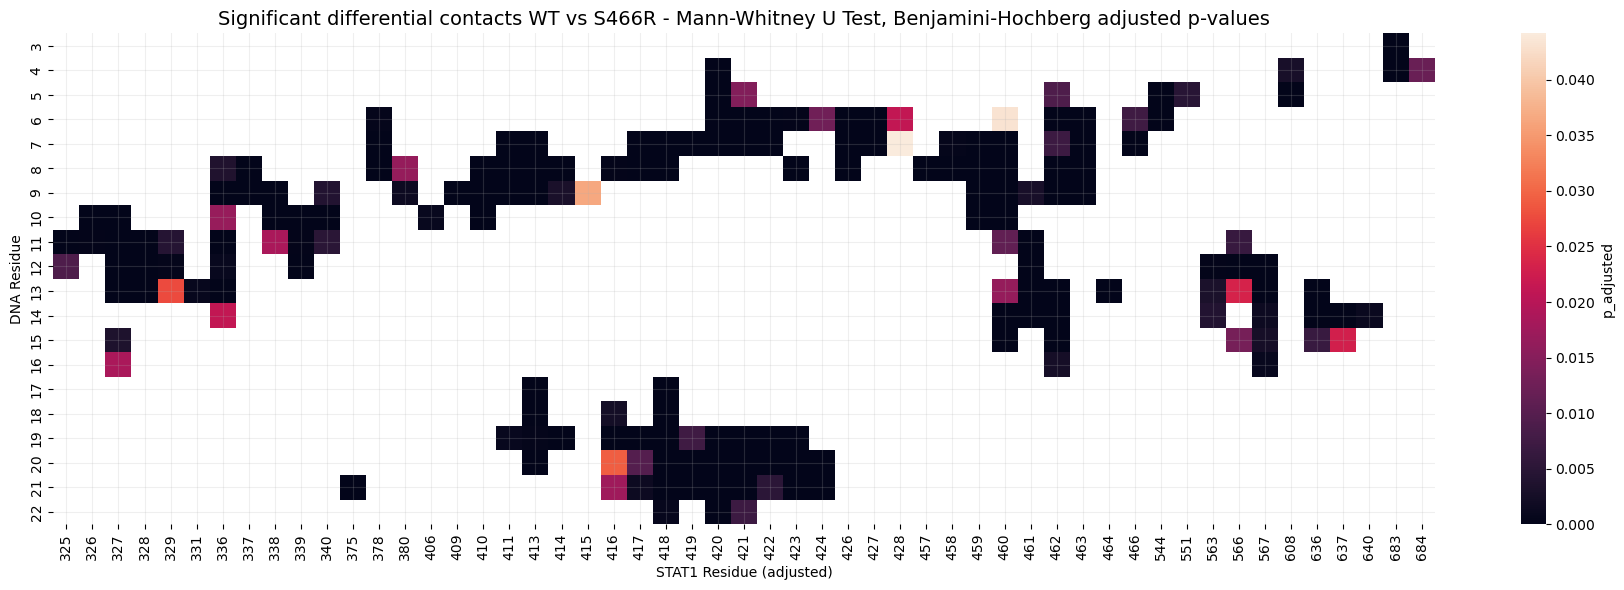

In [74]:
significant_pivot = pivotdf_count_avg_sig_bh(significant)

plt.figure(figsize=(18, 6))

# Chain A
sns.heatmap(significant_pivot, cmap='rocket', cbar_kws={'label': 'p_adjusted'})
plt.title('Significant differential contacts WT vs S466R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

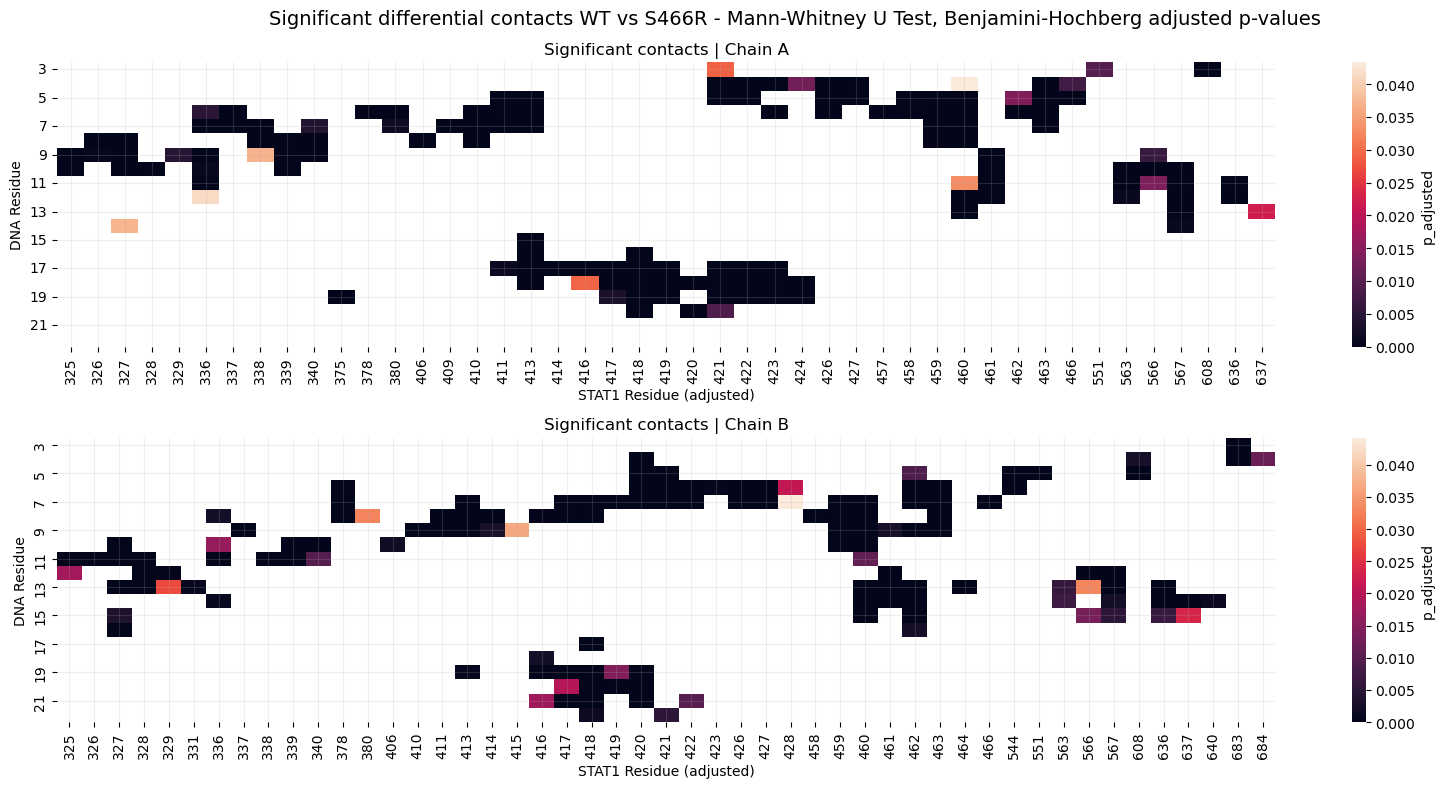

In [75]:
significant_monoA_pivot = pivotdf_count_avg_sig_bh(significant[significant['sele1_chain'] == 'A'])
significant_monoB_pivot = pivotdf_count_avg_sig_bh(significant[significant['sele1_chain'] == 'B'])


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharey=True)

# Chain A
sns.heatmap(significant_monoA_pivot, cmap='rocket', ax=ax1, cbar_kws={'label': 'p_adjusted'})
ax1.set_title('Significant contacts | Chain A')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha=0.2)

# Chain B
sns.heatmap(significant_monoB_pivot, cmap='rocket', ax=ax2, cbar_kws={'label': 'p_adjusted'})
ax2.set_title('Significant contacts | Chain B')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha=0.2)

plt.suptitle('Significant differential contacts WT vs S466R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)

plt.tight_layout()
plt.show()

In [76]:
significant_monoA_dnaC_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'A') & (significant['sele2_chain'] == 'C')])
significant_monoA_dnaD_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'A') & (significant['sele2_chain'] == 'D')])
significant_monoB_dnaC_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'B') & (significant['sele2_chain'] == 'C')])
significant_monoB_dnaD_pivot = pivotdf_count_avg_sig_bh(significant[(significant['sele1_chain'] == 'B') & (significant['sele2_chain'] == 'D')])

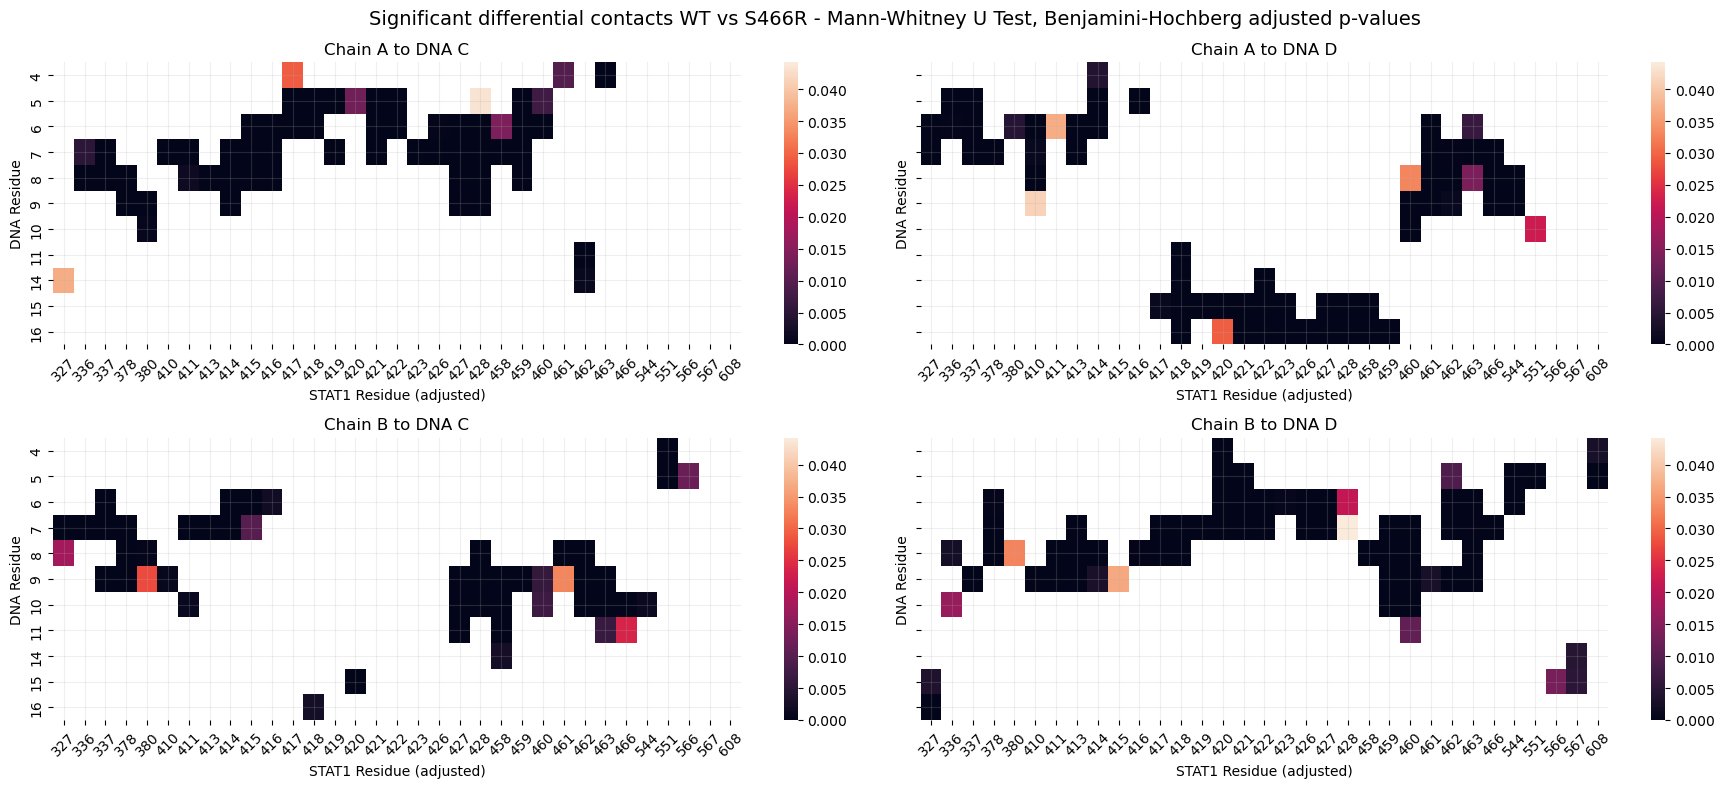

In [77]:
# Find global min and max
all_data = [
    significant_monoA_dnaC_pivot.values,
    significant_monoA_dnaD_pivot.values,
    significant_monoB_dnaC_pivot.values,
    significant_monoB_dnaD_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (significant_monoA_dnaC_pivot, ax1, 'Chain A to DNA C'),
    (significant_monoA_dnaD_pivot, ax2, 'Chain A to DNA D'),
    (significant_monoB_dnaC_pivot, ax3, 'Chain B to DNA C'),
    (significant_monoB_dnaD_pivot, ax4, 'Chain B to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket', 
        ax=ax, 
        cbar=True, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('STAT1 Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.suptitle('Significant differential contacts WT vs S466R - Mann-Whitney U Test, Benjamini-Hochberg adjusted p-values', fontsize=14)
plt.tight_layout()
plt.show()

Two-way ANOVA

In [79]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy.stats import shapiro, levene
import numpy as np

# Add Mutation column to each DataFrame
wt_data['Mutation'] = 'WT'
S466R_data['Mutation'] = 'S466R'

# Combine the DataFrames
combined_df = pd.concat([wt_data[['pair_id', 'distance', 'Mutation']], 
                         S466R_data[['pair_id', 'distance', 'Mutation']]], 
                        ignore_index=True)

# Ensure distance is numeric
combined_df['distance'] = pd.to_numeric(combined_df['distance'], errors='coerce')

# Drop rows with NaN distances (if any)
combined_df = combined_df.dropna(subset=['distance'])

# Check for sufficient data per group (at least 2 observations per Mutation-pair_id combination)
counts = combined_df.groupby(['Mutation', 'pair_id']).size().reset_index(name='count')
valid_pairs = counts[counts['count'] >= 2].groupby('pair_id').size()
valid_pairs = valid_pairs[valid_pairs == 2].index  # Pairs present in both WT and S466R with >=2 observations
combined_df = combined_df[combined_df['pair_id'].isin(valid_pairs)]

# Check if there’s enough data for ANOVA
if combined_df.empty or len(valid_pairs) < 1:
    print("Insufficient data for ANOVA: Need pairs with >=2 observations in both WT and S466R.")
else:
    # Perform two-way ANOVA
    model = ols('distance ~ C(Mutation) + C(pair_id) + C(Mutation):C(pair_id)', data=combined_df).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)

    # Print ANOVA results
    print("Two-Way ANOVA Results:")
    print(anova_table)

    # Optional: Check assumptions
    # Normality test (Shapiro-Wilk) on residuals
    residuals = model.resid
    shapiro_stat, shapiro_p = shapiro(residuals)
    print("\nShapiro-Wilk Test for Normality of Residuals:")
    print(f"Statistic: {shapiro_stat:.4f}, p-value: {shapiro_p:.4f}")
    print("p > 0.05 suggests residuals are normally distributed.")

    # Homogeneity of variances (Levene’s test)
    levene_stat, levene_p = levene(
        *[combined_df[(combined_df['Mutation'] == mut) & (combined_df['pair_id'] == pair)]['distance']
          for mut in combined_df['Mutation'].unique()
          for pair in valid_pairs]
    )
    print("\nLevene’s Test for Homogeneity of Variances:")
    print(f"Statistic: {levene_stat:.4f}, p-value: {levene_p:.4f}")
    print("p > 0.05 suggests equal variances across groups.")

MemoryError: Unable to allocate 78.4 GiB for an array with shape (13128174, 802) and data type float64